# 사과의 특성 7종으로 사과 품질(good/bad)을 구분할 수 있는가

## #1. 분석 개요

**분석 주제**

> 공개 데이터인 Kaggle Apple Quality(4,000건)로 **사과의 크기·무게·단맛·아삭함·과즙·숙성도·산도 7개 특성이 품질(`good`/`bad`)이 될 확률에 어떤 영향을 주는지** 확인한다.
> 종속변수가 두 범주이므로 **로지스틱 회귀**를 사용하며, 결과는 인과가 아닌 **연관 관계**로 해석한다.
> 값은 이미 표준화된 지표로 제공되어 "1 증가"는 원 단위가 아닌 **표준화 점수 1점 증가**를 뜻한다.

**분석 질문**

- **Q1.** 사과가 `good`일 확률을 가장 크게 좌우하는 요인은 무엇인가?
- **Q2.** EDA(T검정)에서 품질과 무관해 보였던 변수(`Weight`·`Acidity`·`Crunchiness`)는 다른 변수를 통제하면 어떻게 되는가?
- **Q3.** 로짓 선형성 가정은 충족되는가? 위배된다면 처방으로 모형 성능이 얼마나 달라지는가?
- **Q4.** 최종 모형의 분류 성능은 어느 정도이며, 임계값은 어떻게 정해야 하는가?

**종속변수:** `Quality` (`good` = 1 / `bad` = 0, 이항형) → 분류 문제

**이번 노트북에서 수행하는 기법**

| 구분 | 내용 |
|---|---|
| 전처리 | 식별자(`A_id`) 제거, 종속변수 범주형 변환, 라벨링(`bad`=0, `good`=1) |
| 이변량 분석 | 연속형 독립변수 7종 → 2집단 종속변수에 대한 **T검정(Welch)·Mann-Whitney U** |
| 다변량 분석 | 독립변수 간 상관분석, **VIF**로 다중공선성 점검 |
| 가정 검정 | **Box-Tidwell** 로짓 선형성 검정, **진단 → 처방(제곱항) → 검증 → 재진단 루프**, 계층 원칙, **Durbin-Watson** |
| 모형 비교 | 전처리를 하나씩 누적한 **체크포인트 8종**(가정 미반영 4종 + 가정 반영 4종) 비교 |
| 해석 | **오즈비(OR)**, **표준화계수(βstd)**, 혼동행렬·AUC, **임계값 조정** |


#### 1-1. 분석 환경 설정

> 분석에 필요한 개별 함수 **import**


In [33]:
from helpers import *
from jussam import load_data
from IPython.display import display, Markdown
from pandas import DataFrame

## #2. 데이터 소개

#### 2-1. 데이터 로딩

In [2]:
origin = load_data("apple_quality")
origin.head()

📚 이 데이터 세트는 다양한 과일 속성에 대한 정보를 담고 있어 과일의 특성을 파악하는 데 도움이 됩니다. 데이터 세트에는 과일 ID, 크기, 무게, 당도, 아삭함, 과즙량, 숙성도, 산도 및 품질과 같은 세부 정보가 포함되어 있습니다. (출처: https://www.kaggle.com/datasets/nelgiriyewithana/apple-quality)

field        description
-----------  ----------------------------------
A_id         각 과일에 대한 고유 식별자
Size         크기
Weight       무게
Sweetness    단맛 정도
Crunchiness  과일의 아삭한 식감을 나타내는 질감
Juiciness    과일의 과즙 함량 정도
Ripeness     과일이 익은 정도
Acidity      과일의 산도 수준
Quality      과일의 전반적인 품질



,A_id,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity,Quality
0,0,-3.970,-2.512,5.346,-1.012,1.845,0.330,-0.492,good
1,1,-1.195,-2.839,3.664,1.588,0.853,0.868,-0.723,good
2,2,-0.292,-1.351,-1.738,-0.343,2.839,-0.038,2.622,bad
3,3,-0.657,-2.272,1.325,-0.098,3.638,-3.414,0.791,good
4,4,1.364,-1.297,-0.385,-0.553,3.031,-1.304,0.502,good


#### 2-2. 변수 정의서

In [3]:
column_means = {
    "A_id":         "사과 식별자",
    "Size":         "크기",
    "Weight":       "무게",
    "Sweetness":    "단맛 정도",
    "Crunchiness":  "아삭한 식감",
    "Juiciness":    "과즙 함량",
    "Ripeness":     "익은 정도",
    "Acidity":      "산도",
    "Quality":      "품질 (good / bad)",
}

#### 2-3. 초기 가설

> 분석 전에 세운 가설이며, 판정은 **7-3. 질문별 답변과 가설 판정**에서 한다.

| 가설 | 내용 |
|---|---|
| H1 | 단맛(`Sweetness`)과 과즙(`Juiciness`)이 높을수록 `good`일 오즈가 증가한다. |
| H2 | 7개 특성 모두 단독으로 품질과 관련이 있다(`good`·`bad` 집단 간 차이가 있다). |
| H3 | 7개 독립변수 모두 로짓 선형성 가정을 충족한다. |
| H4 | 최종 모형은 무조건 `good`이라고 답하는 모형(정확도 50.1%)보다 우수하다. |

## #3. 품질 점검 및 기본 전처리

#### 3-1. 데이터 구조 점검

##### 자료형 확인

In [4]:
origin.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   A_id         4000 non-null   int64  
 1   Size         4000 non-null   float64
 2   Weight       4000 non-null   float64
 3   Sweetness    4000 non-null   float64
 4   Crunchiness  4000 non-null   float64
 5   Juiciness    4000 non-null   float64
 6   Ripeness     4000 non-null   float64
 7   Acidity      4000 non-null   float64
 8   Quality      4000 non-null   str    
dtypes: float64(7), int64(1), str(1)
memory usage: 295.1 KB


##### 자료형 변환

- `A_id`는 **행마다 값이 모두 다른 식별자**이므로 분석 대상이 아니다. 여기서 제거한다.
  - 숫자로 저장되어 있어 그대로 두면 연속형 독립변수로 잘못 투입된다.
- 종속변수 `Quality`는 문자열이므로 **명목형(category)** 으로 변환한다.

In [5]:
df0 = origin.drop(columns=["A_id"])
df1 = my_qtcheck.set_type(df0, as_category=["Quality"])

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   Size         4000 non-null   float64 
 1   Weight       4000 non-null   float64 
 2   Sweetness    4000 non-null   float64 
 3   Crunchiness  4000 non-null   float64 
 4   Juiciness    4000 non-null   float64 
 5   Ripeness     4000 non-null   float64 
 6   Acidity      4000 non-null   float64 
 7   Quality      4000 non-null   category
dtypes: category(1), float64(7)
memory usage: 222.8 KB


#### 3-2. 데이터 품질 점검

##### 데이터 중복 점검

In [6]:
df2 = my_qtcheck.check_duplicates(df1)
df2.head()

중복된 행의 수: 0


,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity,Quality
0,-3.970,-2.512,5.346,-1.012,1.845,0.330,-0.492,good
1,-1.195,-2.839,3.664,1.588,0.853,0.868,-0.723,good
2,-0.292,-1.351,-1.738,-0.343,2.839,-0.038,2.622,bad
3,-0.657,-2.272,1.325,-0.098,3.638,-3.414,0.791,good
4,1.364,-1.297,-0.385,-0.553,3.031,-1.304,0.502,good


##### 결측치 점검

In [7]:
my_qtcheck.check_missing_values(df2)

,Missing Count,Missing Ratio (%)
Size,0,0.000
Weight,0,0.000
Sweetness,0,0.000
Crunchiness,0,0.000
Juiciness,0,0.000
Ripeness,0,0.000
Acidity,0,0.000
Quality,0,0.000


> 중복도 결측치도 없다. 캐글 데이터셋 중에서는 드물게 **정제가 이미 끝난 상태**다.

#### 3-3. 기술통계량

##### 명목형 변수의 기술 통계량

In [8]:
cat_desc = my_qtcheck.categorical_summary(df2)
cat_desc

컬럼 'Quality'의 value_counts( ):


,count
Quality,
bad,1996
good,2004


,Quality
count,4000
unique,2
top,good
freq,2004


##### 연속형 변수의 기술 통계량

In [9]:
num_desc = my_qtcheck.numerical_summary(df2)
num_desc.T

,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity
count,4000.000,4000.000,4000.000,4000.000,4000.000,4000.000,4000.000
mean,-0.503,-0.990,-0.470,0.985,0.512,0.498,0.077
std,1.928,1.603,1.943,1.403,1.930,1.874,2.110
min,-7.152,-7.150,-6.894,-6.055,-5.962,-5.865,-7.011
25%,-1.817,-2.012,-1.738,0.063,-0.801,-0.772,-1.377
50%,-0.514,-0.985,-0.505,0.998,0.534,0.503,0.023
75%,0.806,0.031,0.802,1.894,1.836,1.766,1.510
max,6.406,5.791,6.375,7.620,7.364,7.238,7.405
rel_diff,-0.021,-0.005,-0.068,0.013,0.041,0.010,2.400
rdiff_flag,similar,similar,similar,similar,similar,similar,large_diff


#### 3-4. 이 장의 결론 — 품질 점검 결과

| 점검 항목 | 결과 |
|---|---|
| 관측치 수 | 4,000건 (중복 0건, 결측 0건) |
| 식별자 | `A_id` 제거 |
| 종속변수 | `Quality` — `good` 2,004건 / `bad` 1,996건 |
| 연속형 독립변수 | 7종 (`Size` ~ `Acidity`) |
| 왜도 | 7종 **모두 `symmetric`** (\|왜도\| < 0.15) → 로그변환 대상 없음 |
| 이상치 | 7종 모두 **1.3% 이하** → 대체 여부는 뒤에서 체크포인트로 비교 |

- 값의 범위가 대략 −7 ~ +7이고 평균이 0 부근이다. **원 단위가 아니라 이미 표준화된 지표**로 제공된 데이터다.
  - 따라서 "크기 1 증가"는 mm나 g가 아니라 **표준화 점수 1점 증가**로 읽어야 한다.
- 종속변수가 **2,004 : 1,996으로 거의 완벽하게 균형**이다.
  - 정확도(Accuracy)의 함정(불균형 데이터에서 게으른 모형이 높은 점수를 받는 문제)이 **이 데이터에서는 발생하지 않는다.**

## #4. 탐색적 데이터 분석 (EDA)

#### 4-1. 변수 유형 분류와 EDA 범위

##### 변수 유형 분류

In [10]:
target = "Quality"    # 종속변수
target_is_continuous = False    # 종속변수 연속형 여부  --> 로지스틱이므로 False
nominal_cols = my_qtcheck.get_categorical_column_names(df2) # 명목형 변수
continuous_cols = my_qtcheck.get_number_column_names(df2)   # 연속형 변수

if target_is_continuous:
    continuous_cols.remove(target)  # 연속형 변수 이름에서 종속변수 항목 제거
else:
    nominal_cols.remove(target)     # 명목형 변수 이름에서 종속변수 항목 제거

print("종속변수 :", target)
print("종속변수 유형: " + ("연속형" if target_is_continuous else "명목형"))
print("명목형   :", nominal_cols)
print("연속형   :", continuous_cols)

종속변수 : Quality
종속변수 유형: 명목형
명목형   : []
연속형   : ['Size', 'Weight', 'Sweetness', 'Crunchiness', 'Juiciness', 'Ripeness', 'Acidity']


##### 서열척도 적용 (필요에 따라 수행)

- 명목형 범주에 순서가 있다면 순서를 지정한다. (도메인 지식이 필요한 부분)
- 이 데이터셋에는 **서열척도 대상이 없다.** 코드는 다른 데이터셋에 그대로 옮겨 쓸 수 있도록 남겨 둔다.

In [11]:
# 서열척도를 적용할 변수와 순서를 정의한다. (낮은 등급 → 높은 등급)
# -> 도메인 지식이 필요한 부분이다.
# -> 서열척도 대상이 없는 데이터셋이라면 빈 딕셔너리로 둔다.
ordinal_map = {}

# 정의된 내용에 따라 순서를 재지정한다.
# -> 데이터셋에 없는 컬럼은 건너뛰므로 다른 데이터셋에서도 오류가 나지 않는다.
df = df2.copy()

for col, order in ordinal_map.items():
    if col in df.columns:
        print(f"'{col}' 컬럼 순서 재지정 : {order}")
        df[col] = df[col].cat.reorder_categories(order, ordered=True)

##### EDA 범위 정리

| 종속유형 | 독립유형 | 분석 유형 | 대상 변수 | 적용 여부 | 비고 |
|---|---|---|---|---|---|
| 연속형 | 연속형 | 상관분석 | — | ❌ 미적용 | 종속변수 타입이 명목형 |
| 연속형 | 명목형(2집단) | T검정 | — | ❌ 미적용 | 종속변수 타입이 명목형 |
| 연속형 | 명목형(3집단+) | ANOVA | — | ❌ 미적용 | 종속변수 타입이 명목형 |
| **명목형(2집단)** | **연속형** | **T검정** | 연속형 독립변수 7종 → `Quality` | ✅ **적용** | 이 데이터의 핵심 |
| 명목형(2집단) | 명목형(2집단) | 교차분석 | — | ❌ 미적용 | 명목형 독립변수 없음 |
| 명목형(2집단) | 명목형(3집단+) | 교차분석 | — | ❌ 미적용 | 명목형 독립변수 없음 |
| 명목형(3집단+) | 연속형 | ANOVA | — | ❌ 미적용 | 종속변수가 2집단 |
| 명목형(3집단+) | 명목형(2집단) | 교차분석 | — | ❌ 미적용 | 종속변수가 2집단 |
| 명목형(3집단+) | 명목형(3집단+) | 교차분석 | — | ❌ 미적용 | 종속변수가 2집단 |

- 종속변수 `Quality`가 **명목형 2집단**이므로 4~6행만 후보가 되고, 그 중 독립변수가 실제로 존재하는 **T검정**만 수행된다.
- **주의** — 종속변수가 명목형이면 **상관분석(피어슨·스피어만)을 쓸 수 없다.**
  상관계수는 두 변수가 모두 연속형일 때 정의되는 지표이기 때문이다.

#### 4-2. 분포 확인 (단변량 분석)

##### 명목형 종속변수에 대한 단변량 분석

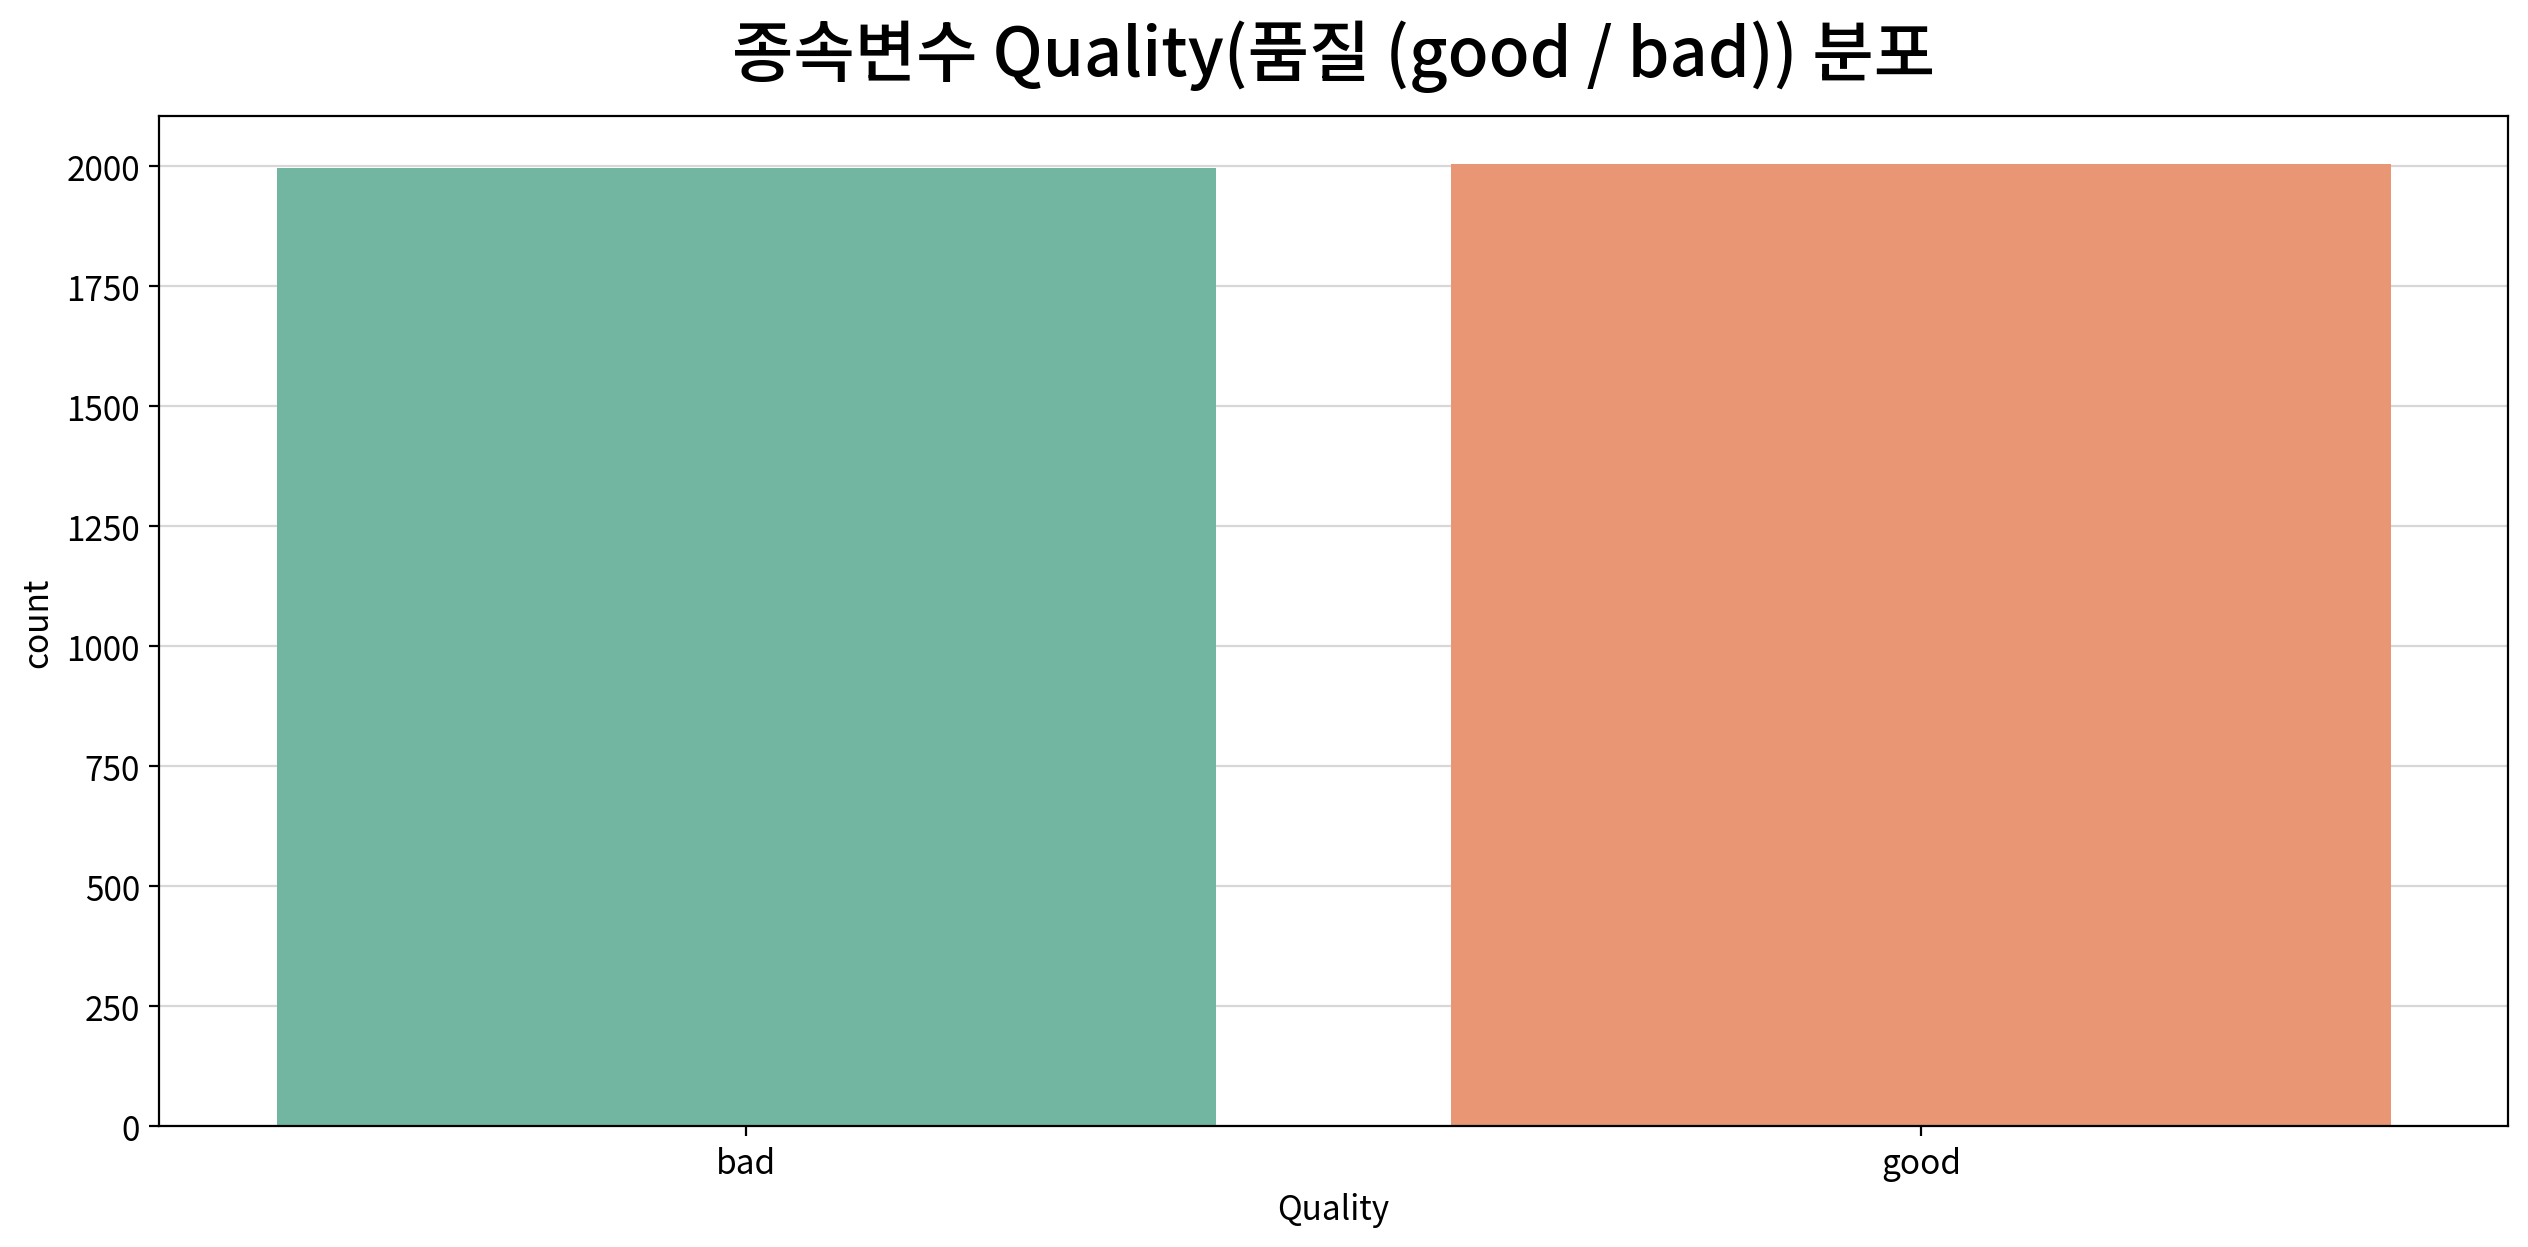

,count,unique,top,freq
Quality,4000,2,good,2004


,빈도,비율
Quality,,
good,2004,0.501
bad,1996,0.499


In [12]:
# 명목형 분포는 카운트 플롯으로 처리한다.
my_plot.countplot(data=df, x=target, hue=target, palette="Set2",
                  title=f"종속변수 {target}({column_means[target]}) 분포")

# 명목형 기술통계량
display(cat_desc[[target]].T)

# 추가적으로 빈도표 생성
freq = df[target].value_counts().rename("빈도").to_frame()
# value_counts(normalize=True)
# --> 전체 고유값의 개수(빈도수) 대신 전체 데이터의 비율을 계산
freq["비율"] = df[target].value_counts(normalize=True)
display(freq)

#### 💡 인사이트

| 점검 항목 | `Quality` 관찰값 |
|---|---|
| 범주 수 | 2 (`good` / `bad`) → **이분형** 이므로 로지스틱 회귀 적용 가능 |
| 최빈 범주 | `good` 2,004건 (50.1%) |
| 최소 범주 | `bad` 1,996건 (49.9%) |
| 균형 여부 | **거의 완벽한 균형** (차이 8건, 0.2%p) |

- 균형 데이터이므로 **정확도(Accuracy)를 그대로 신뢰해도 되는 드문 경우**다.
  - 무조건 `good`이라고만 답하는 게으른 모형의 정확도는 **50.1%** 에 그친다.
  - 즉 정확도 50%가 이 데이터의 **바닥값(baseline)** 이고, 모형은 그보다 얼마나 올라가는지로 평가한다.

##### 연속형 독립변수에 대한 단변량 분석

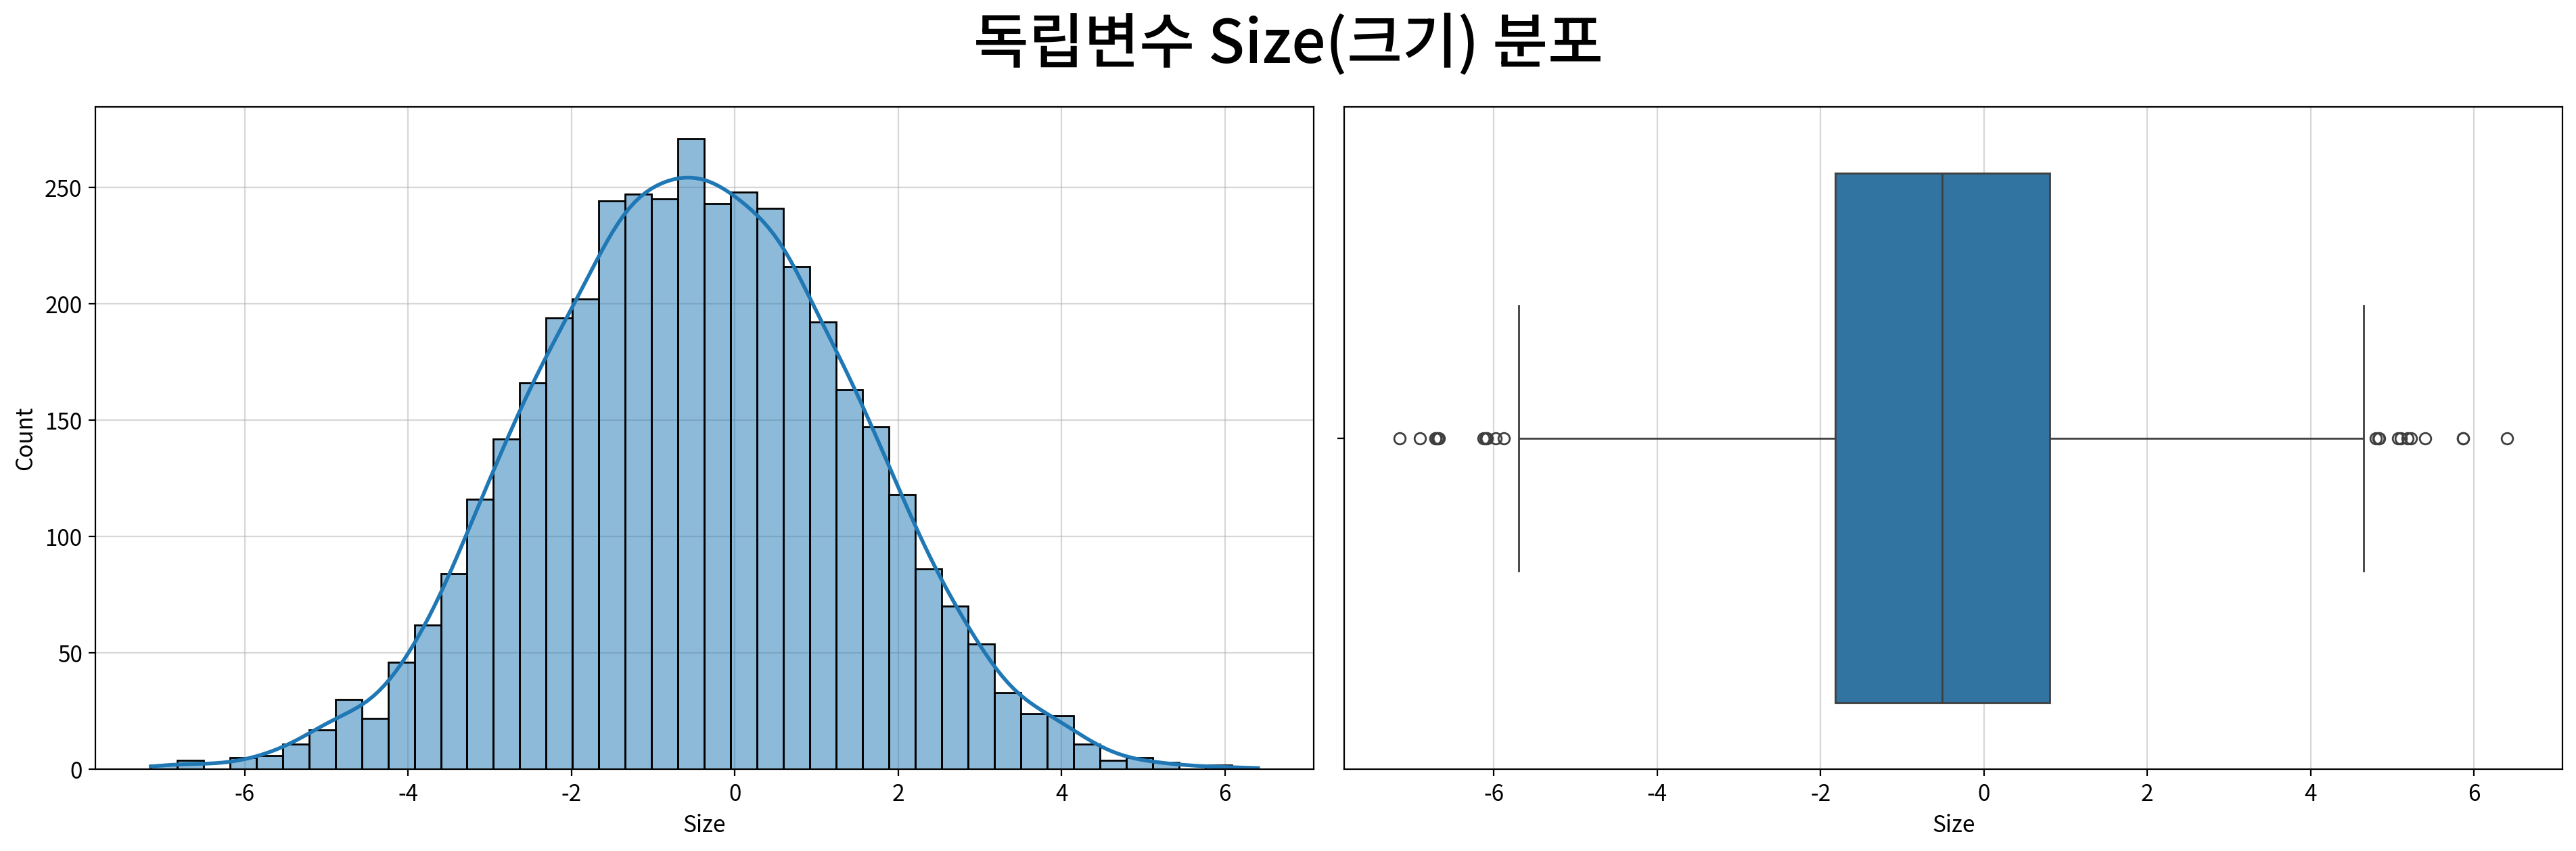

,Size
count,4000.000
mean,-0.503
std,1.928
min,-7.152
25%,-1.817
50%,-0.514
75%,0.806
max,6.406
rel_diff,-0.021
rdiff_flag,similar


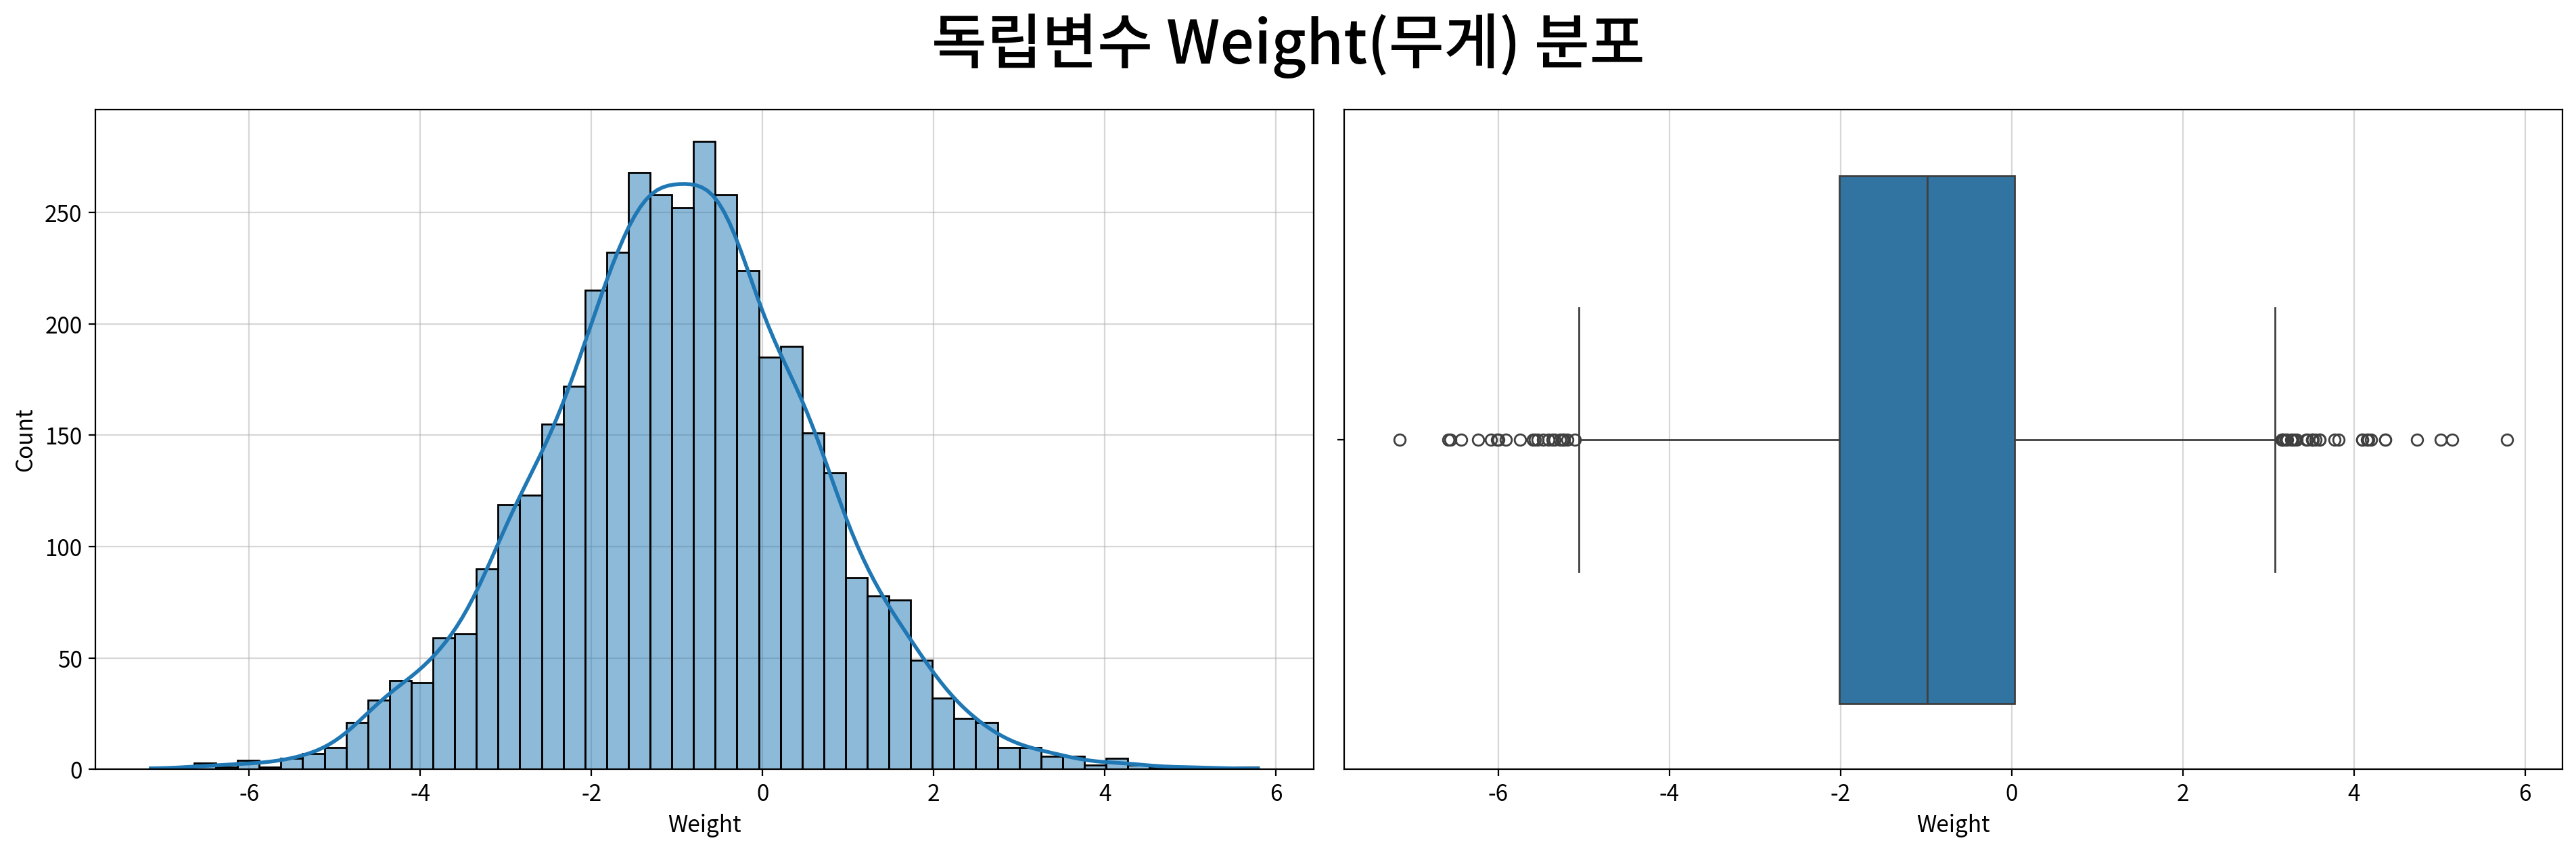

,Weight
count,4000.000
mean,-0.990
std,1.603
min,-7.150
25%,-2.012
50%,-0.985
75%,0.031
max,5.791
rel_diff,-0.005
rdiff_flag,similar


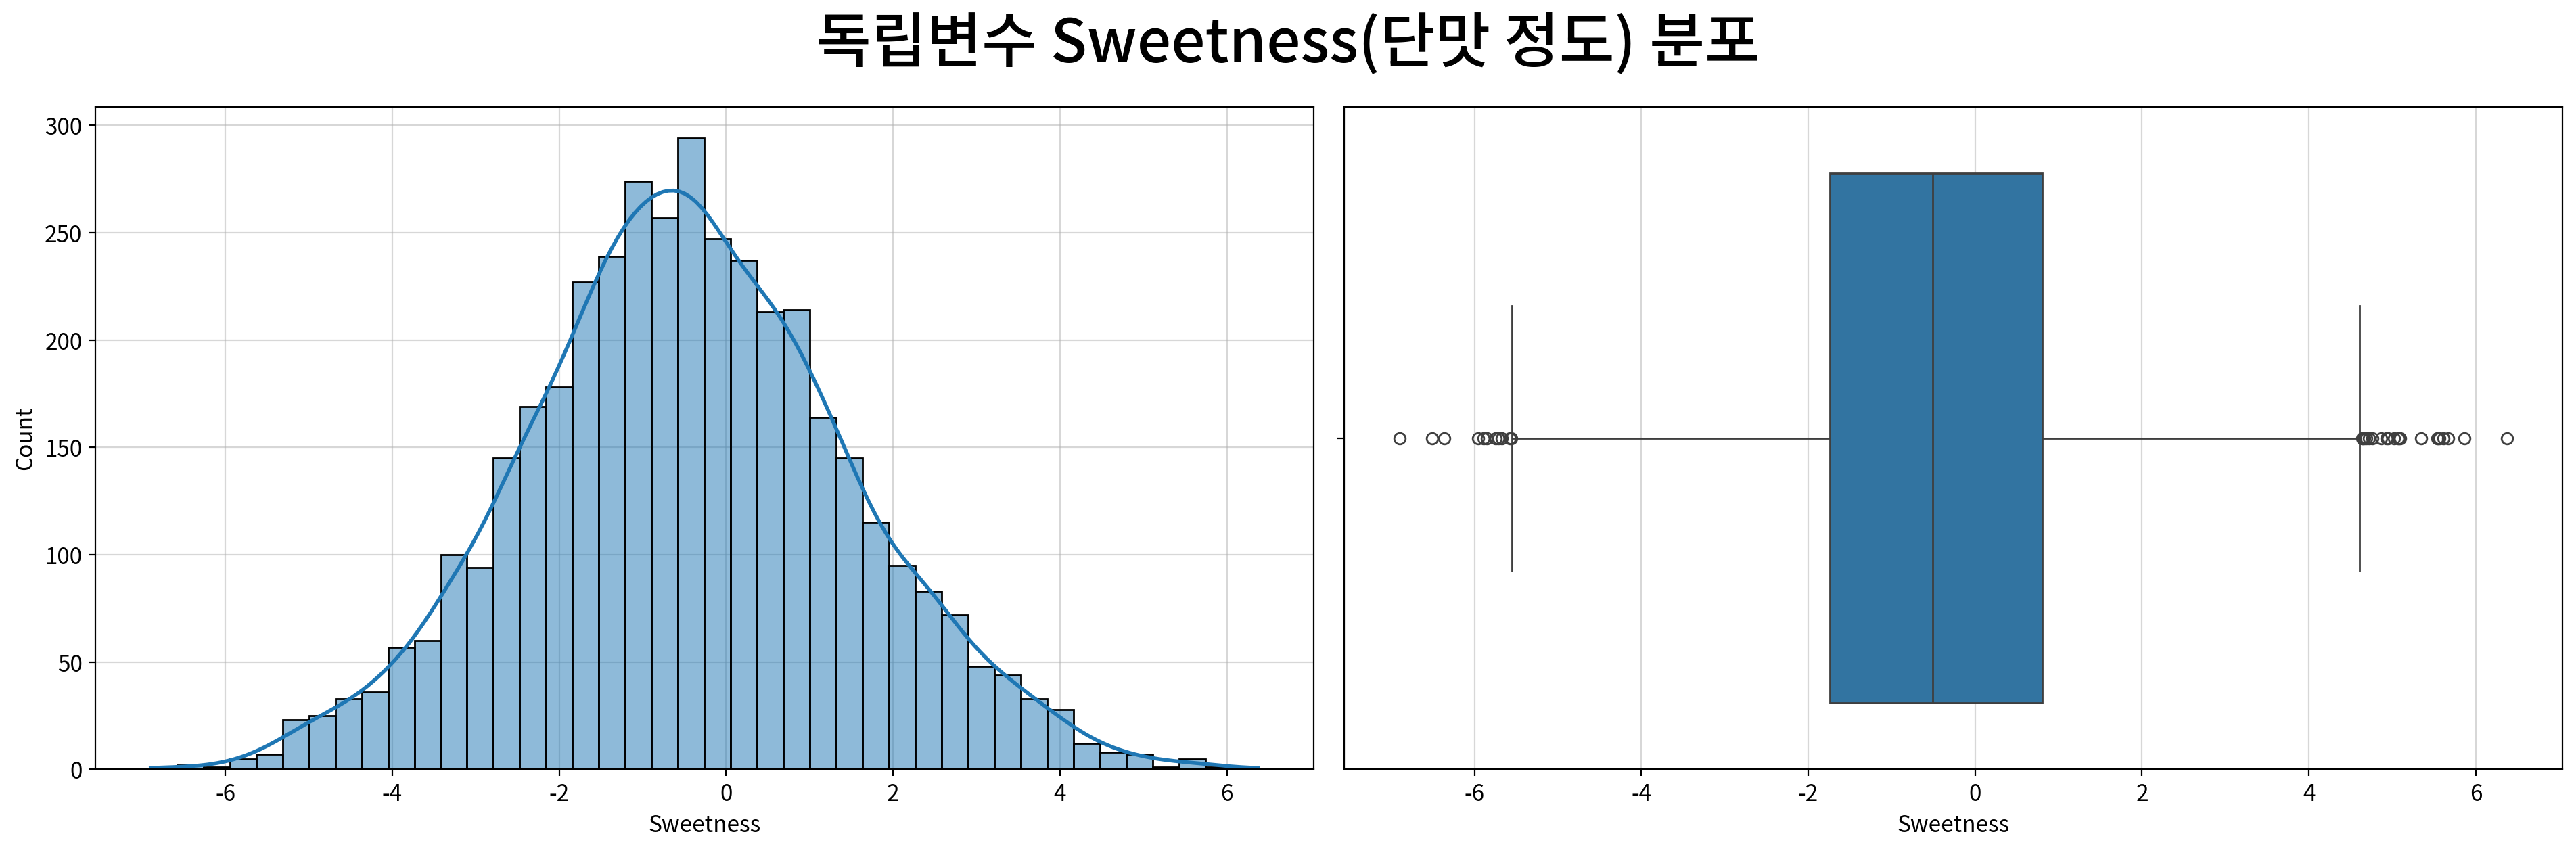

,Sweetness
count,4000.000
mean,-0.470
std,1.943
min,-6.894
25%,-1.738
50%,-0.505
75%,0.802
max,6.375
rel_diff,-0.068
rdiff_flag,similar


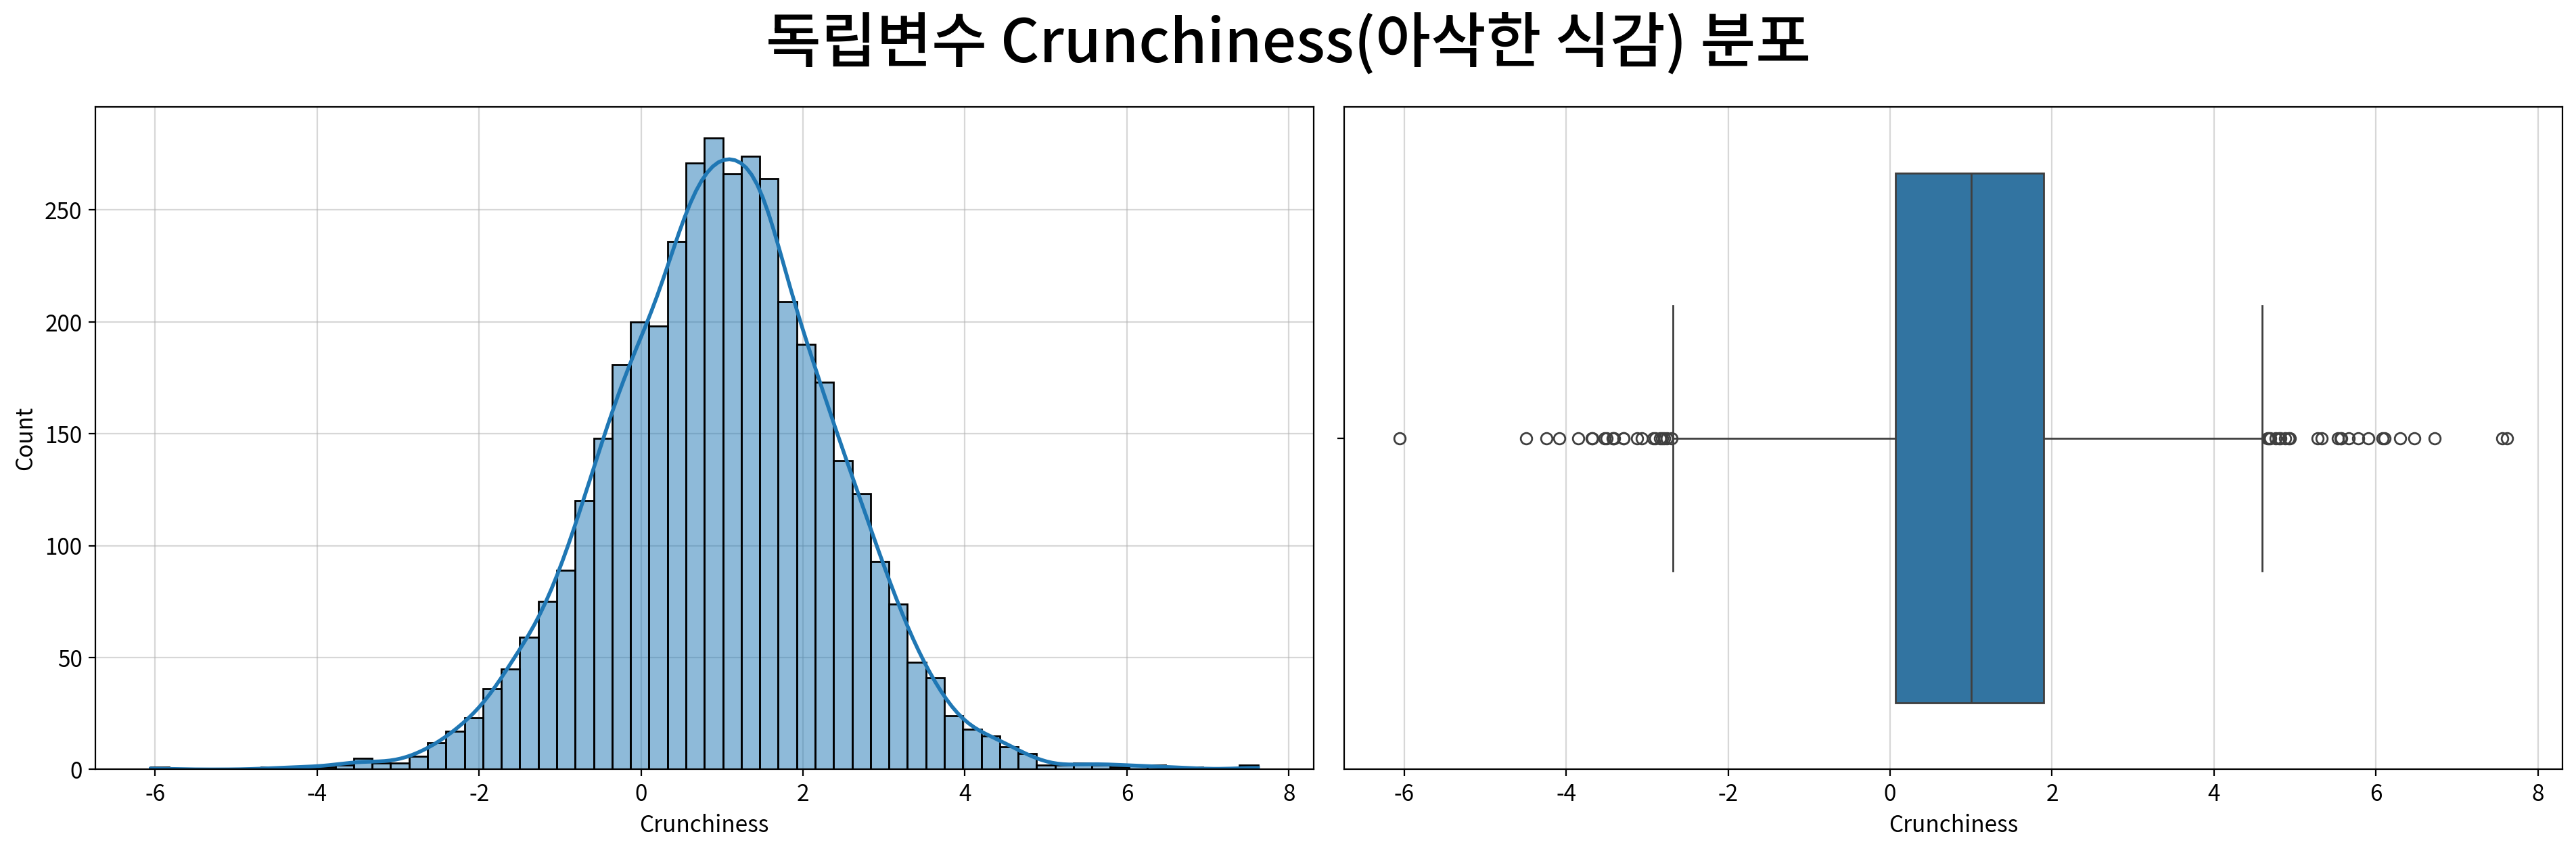

,Crunchiness
count,4000.000
mean,0.985
std,1.403
min,-6.055
25%,0.063
50%,0.998
75%,1.894
max,7.620
rel_diff,0.013
rdiff_flag,similar


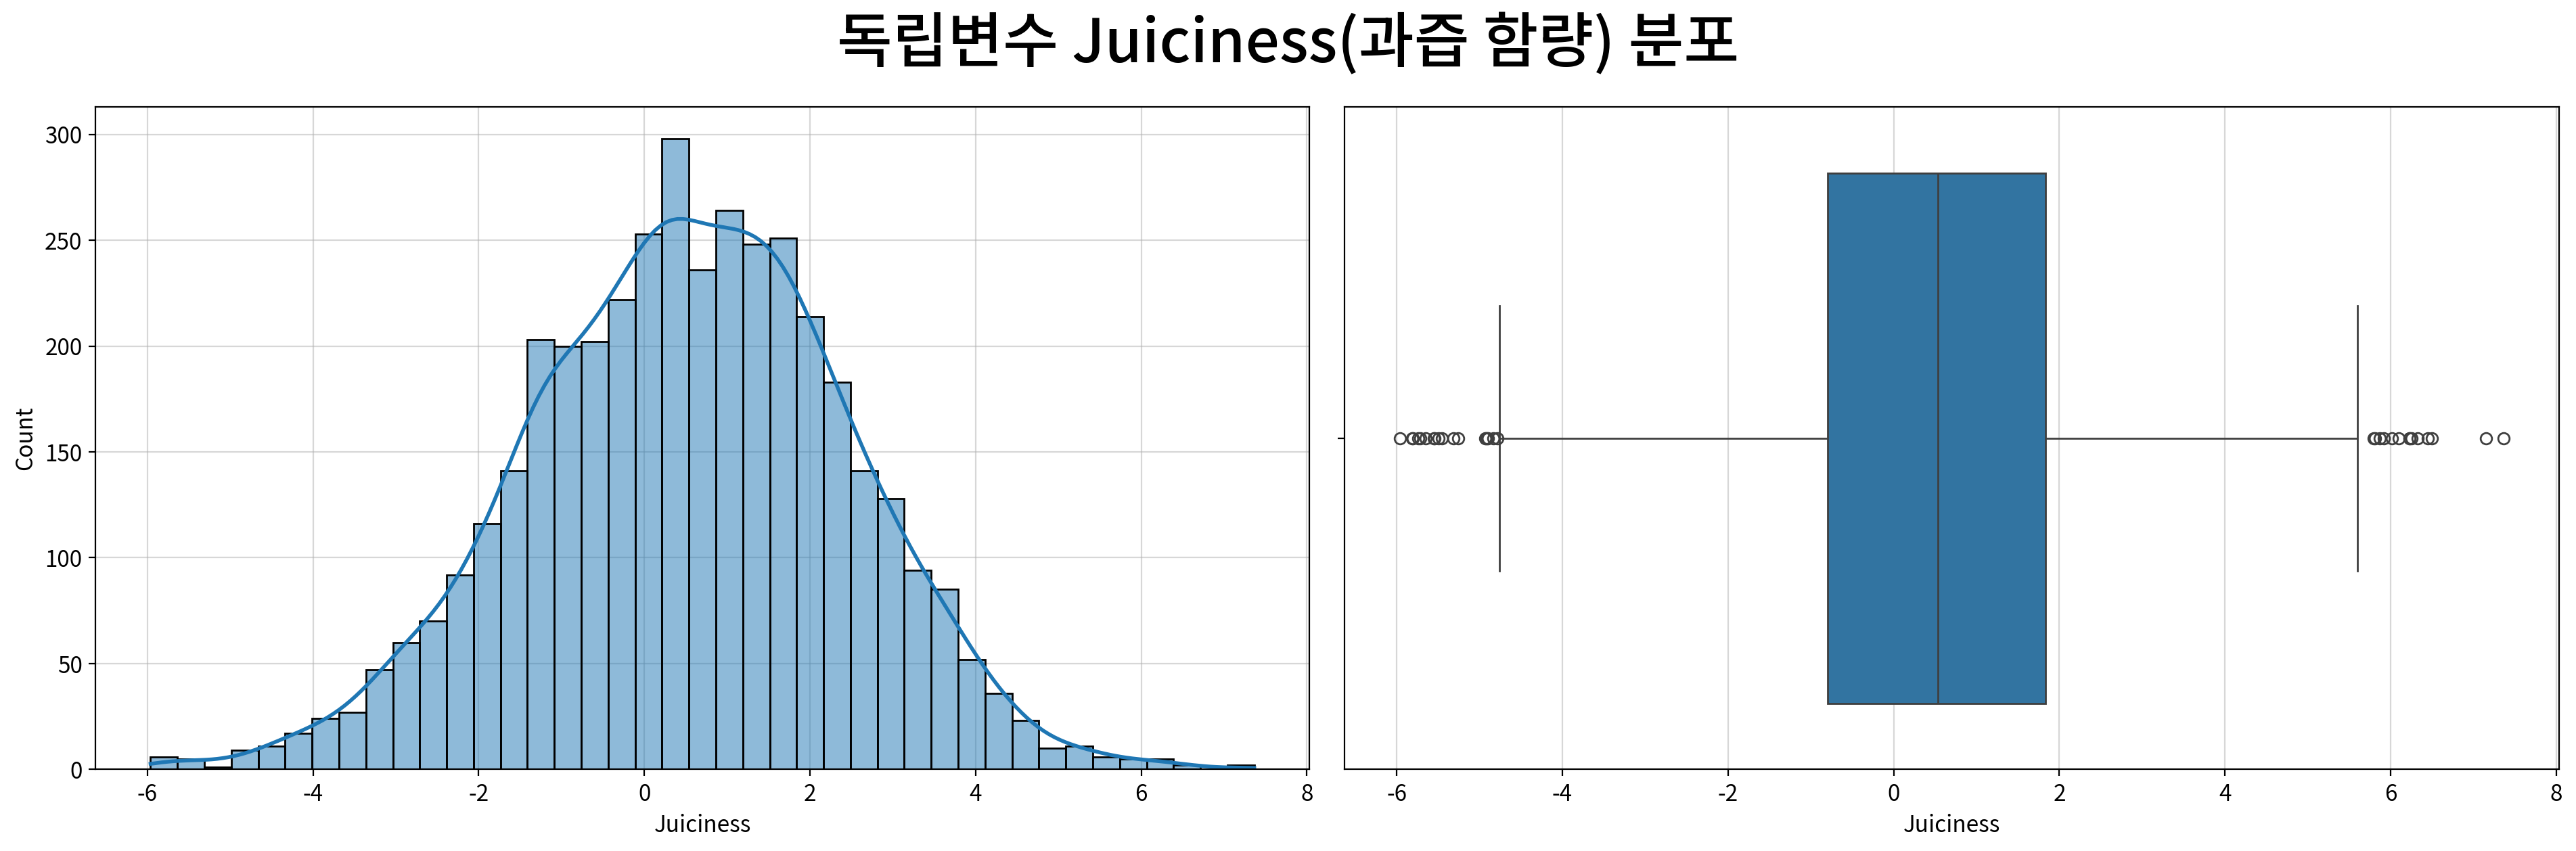

,Juiciness
count,4000.000
mean,0.512
std,1.930
min,-5.962
25%,-0.801
50%,0.534
75%,1.836
max,7.364
rel_diff,0.041
rdiff_flag,similar


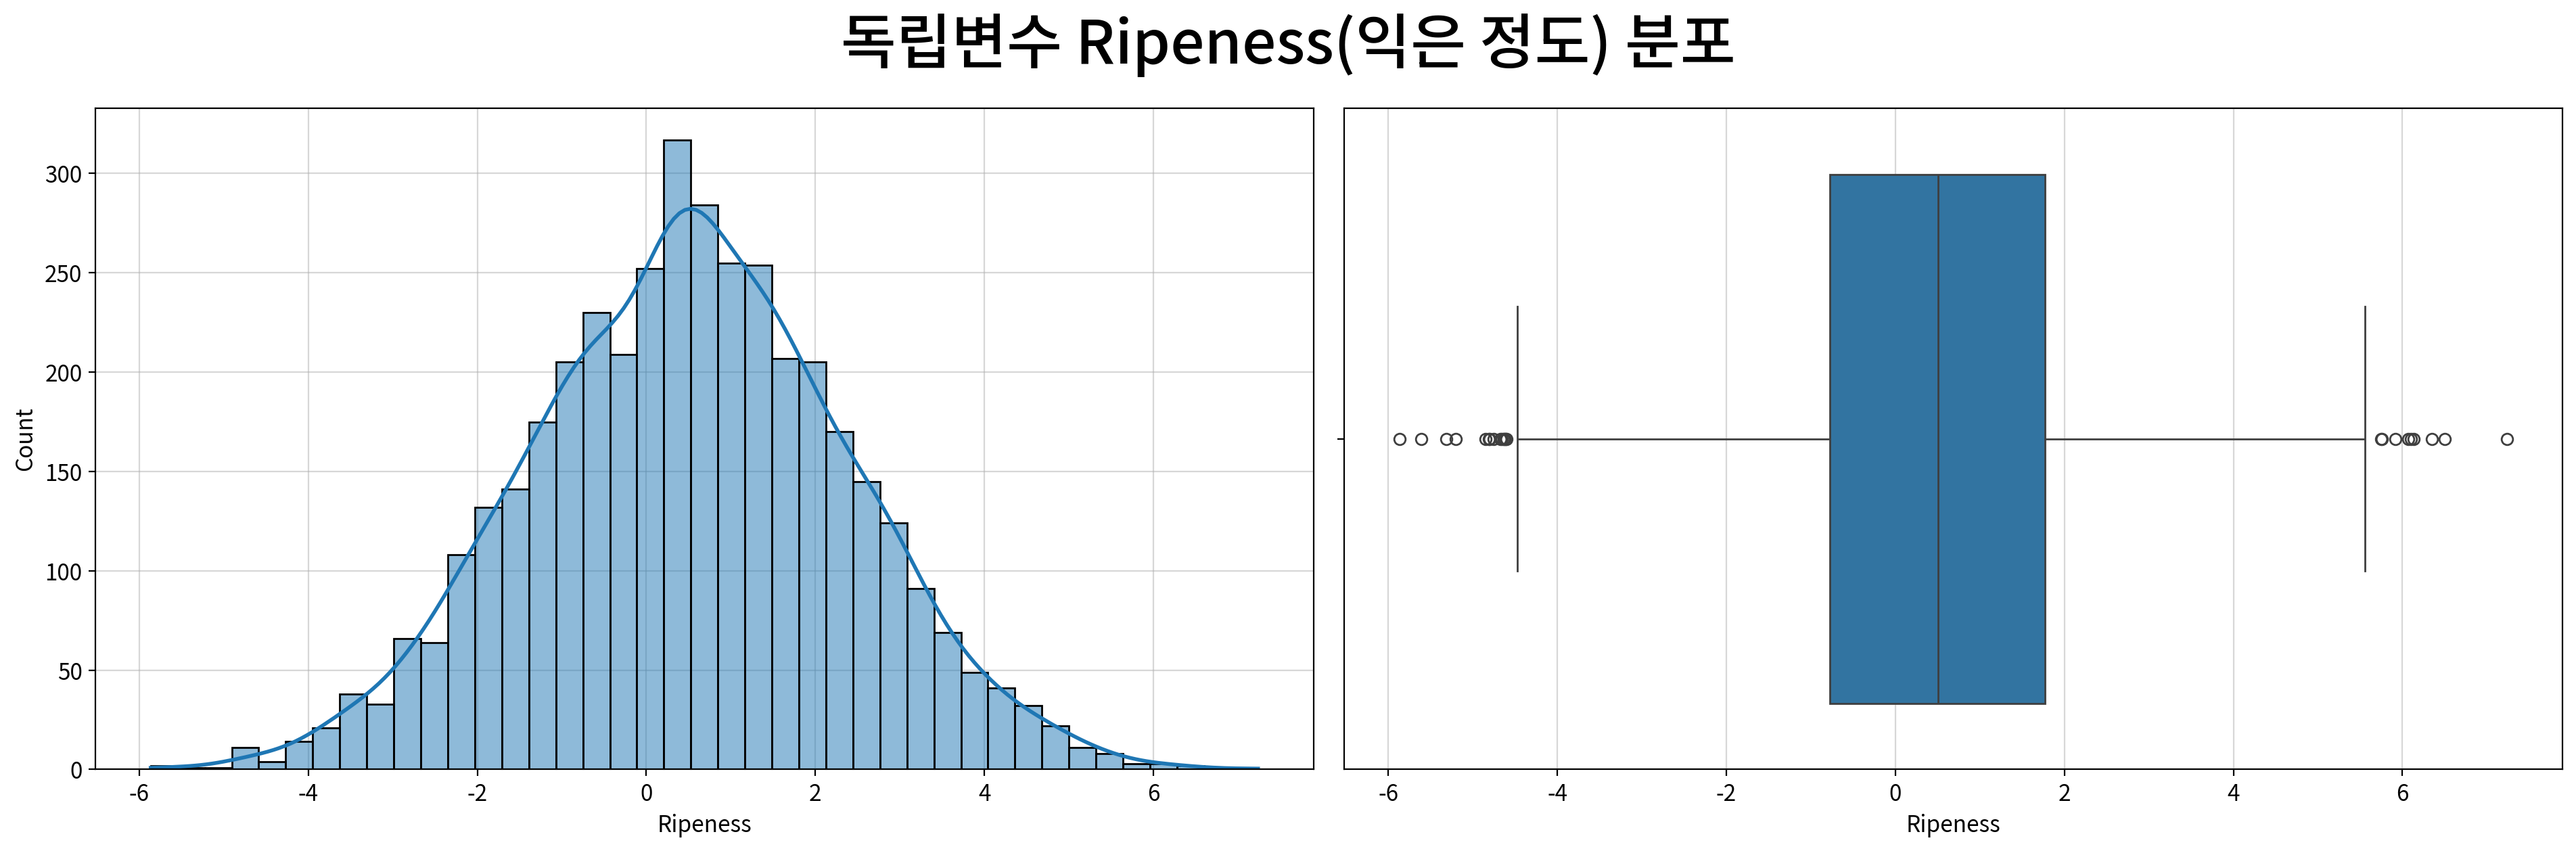

,Ripeness
count,4000.000
mean,0.498
std,1.874
min,-5.865
25%,-0.772
50%,0.503
75%,1.766
max,7.238
rel_diff,0.010
rdiff_flag,similar


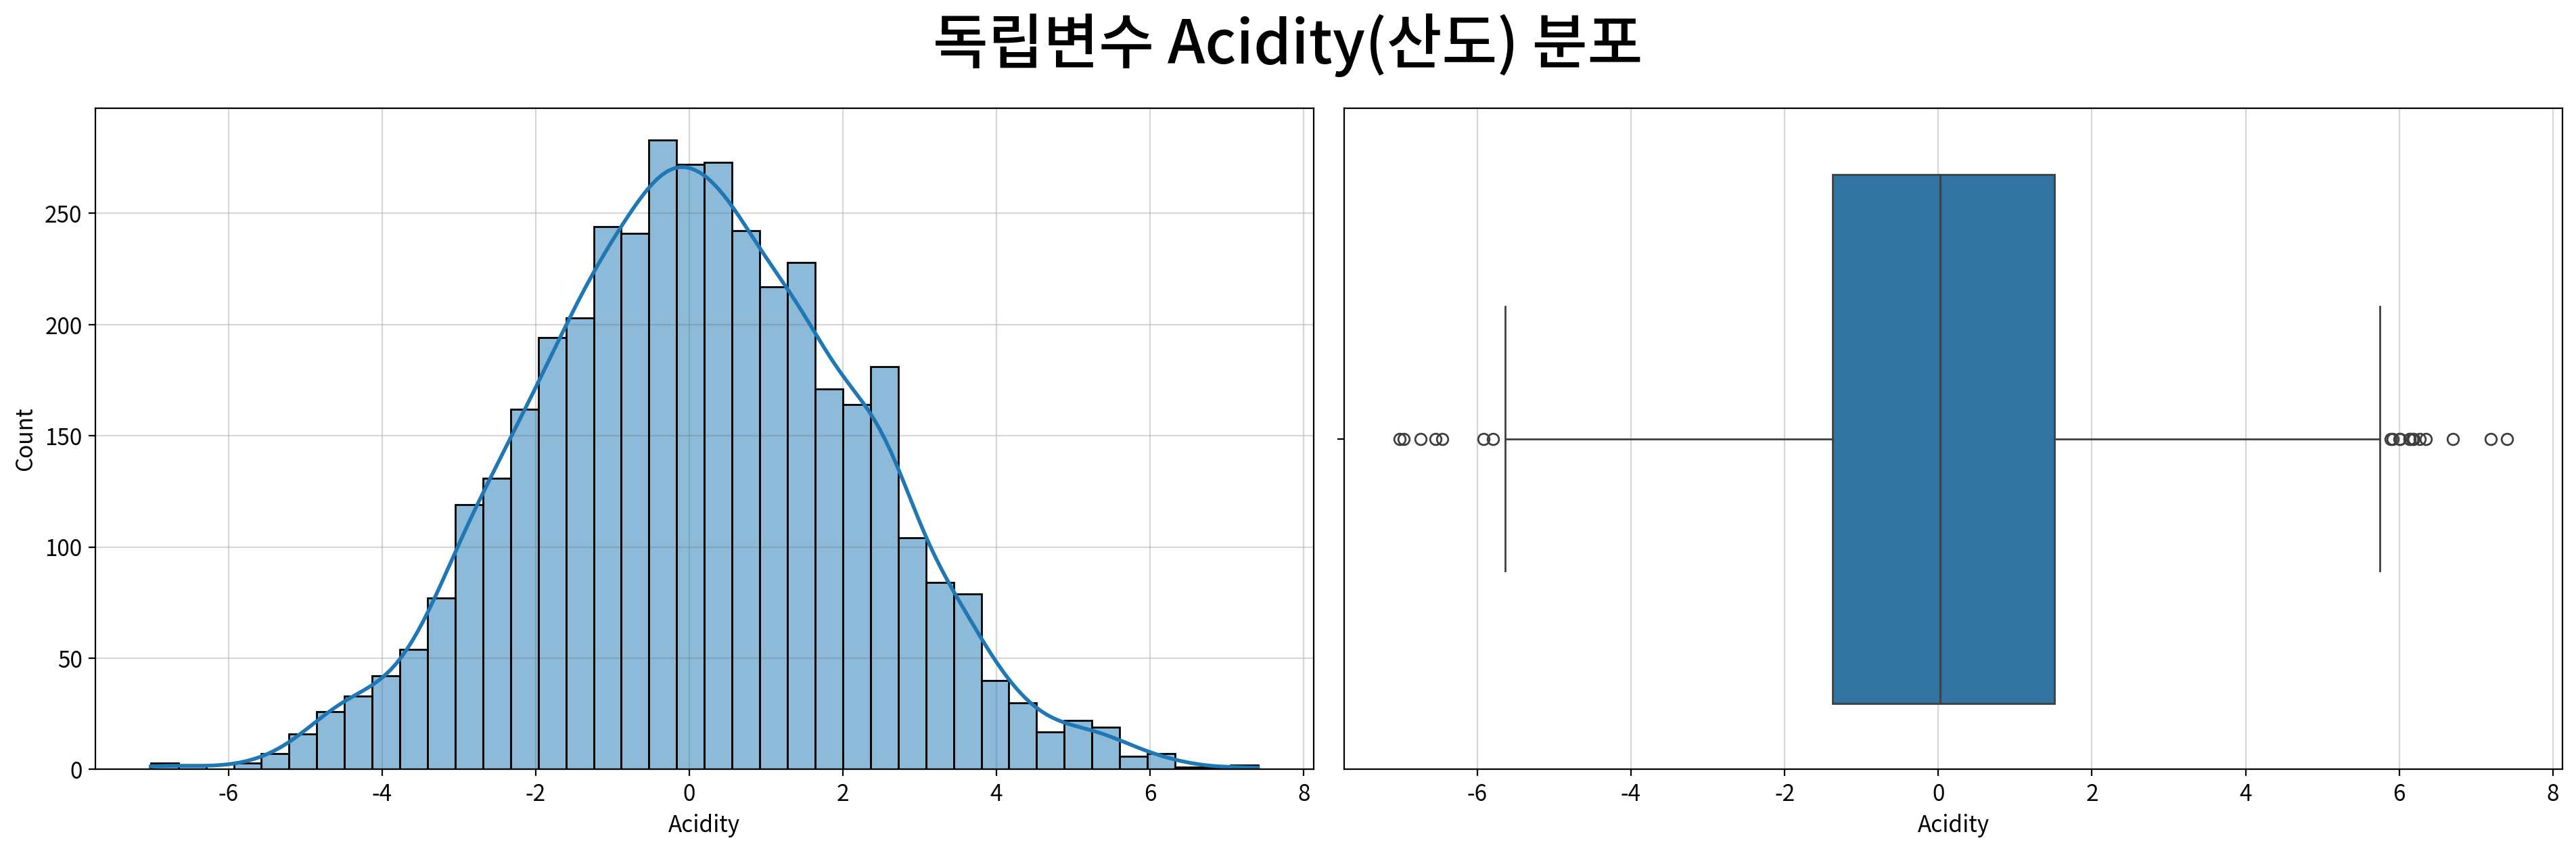

,Acidity
count,4000.000
mean,0.077
std,2.110
min,-7.011
25%,-1.377
50%,0.023
75%,1.510
max,7.405
rel_diff,2.400
rdiff_flag,large_diff


In [13]:
for f in continuous_cols:
    fig, ax = my_plot.init(rows=1, cols=2, width=960, height=640,
                title=f"독립변수 {f}({column_means[f]}) 분포")
    my_plot.histplot(data=df, x=f, kde=True, ax=ax[0])
    my_plot.boxplot(data=df, x=f, ax=ax[1])
    my_plot.show()

    display(num_desc[num_desc.index == f].T)

#### 💡 인사이트

| 변수 | 분포 모양(왜도) | 봉우리 수 | 이상치 | 판단·조치 |
|---|---|---|---|---|
| `Size` | 대칭 (−0.002) | 단봉 | 22건 (0.5%) | 변환 불필요 |
| `Weight` | 대칭 (+0.003) | 단봉 | 54건 (1.3%) | 변환 불필요 |
| `Sweetness` | 대칭 (+0.084) | 단봉 | 32건 (0.8%) | 변환 불필요 |
| `Crunchiness` | 대칭 (0.000) | 단봉 | 47건 (1.2%) | 변환 불필요 |
| `Juiciness` | 대칭 (−0.113) | 단봉 | 32건 (0.8%) | 변환 불필요 |
| `Ripeness` | 대칭 (−0.009) | 단봉 | 24건 (0.6%) | 변환 불필요 |
| `Acidity` | 대칭 (+0.056) | 단봉 | 20건 (0.5%) | 변환 불필요 |

#### 4-3. 변수 간 관계 (이변량 분석)

##### T-Test (x: 연속형 독립변수 → y: 2집단 명목형 종속변수)

#### ▶︎ Size(크기) → Quality

statistic  p-value  significant      result
test                alternative                                              
Mann-Whitney U test two-sided   1433524.000    0.000         True  bad ≠ good
                    less        1433524.000    0.000         True  bad < good
                    greater     1433524.000    1.000        False  bad ≤ good

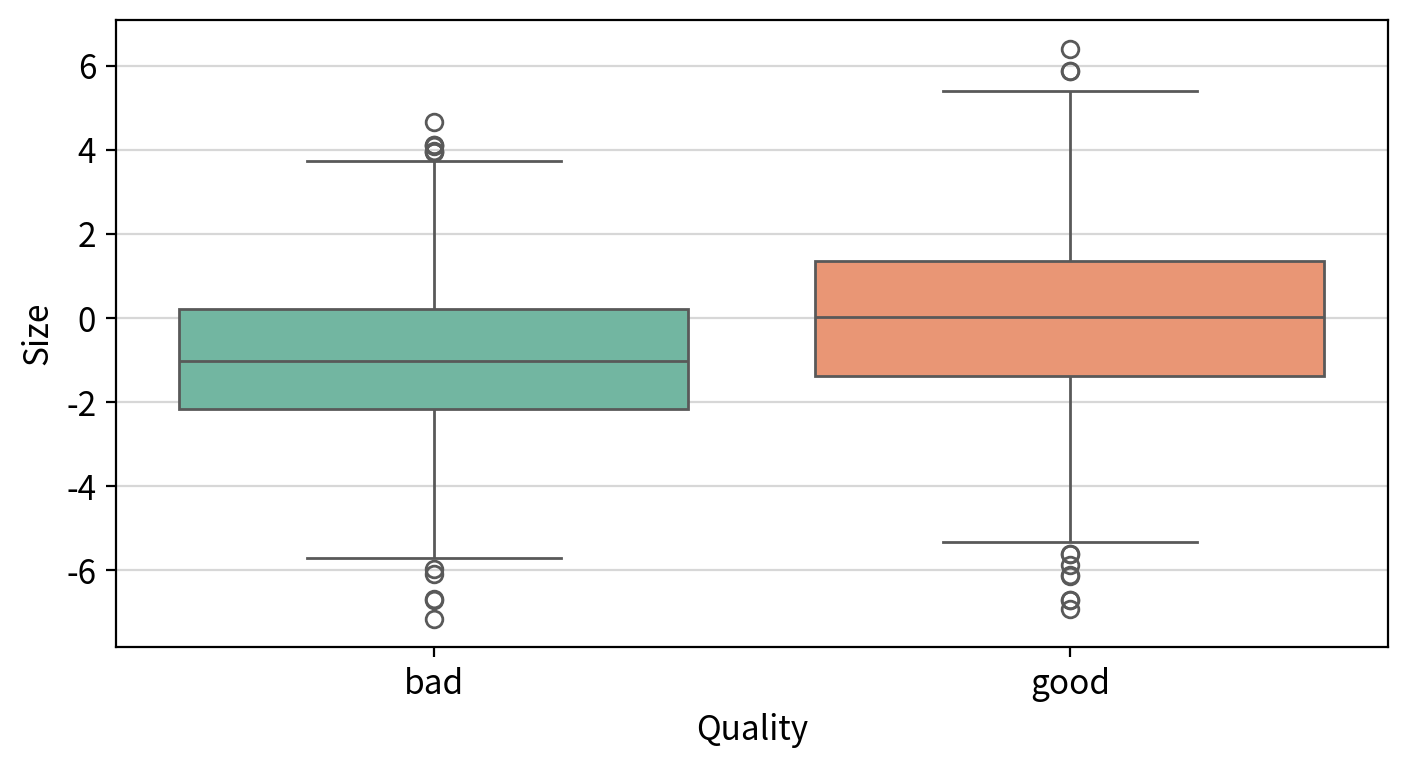

#### ▶︎ Weight(무게) → Quality

statistic  p-value  significant      result
test         alternative                                             
Welch t-test two-sided       -0.090    0.928        False  bad = good
             less            -0.090    0.464        False  bad ≥ good
             greater         -0.090    0.536        False  bad ≤ good

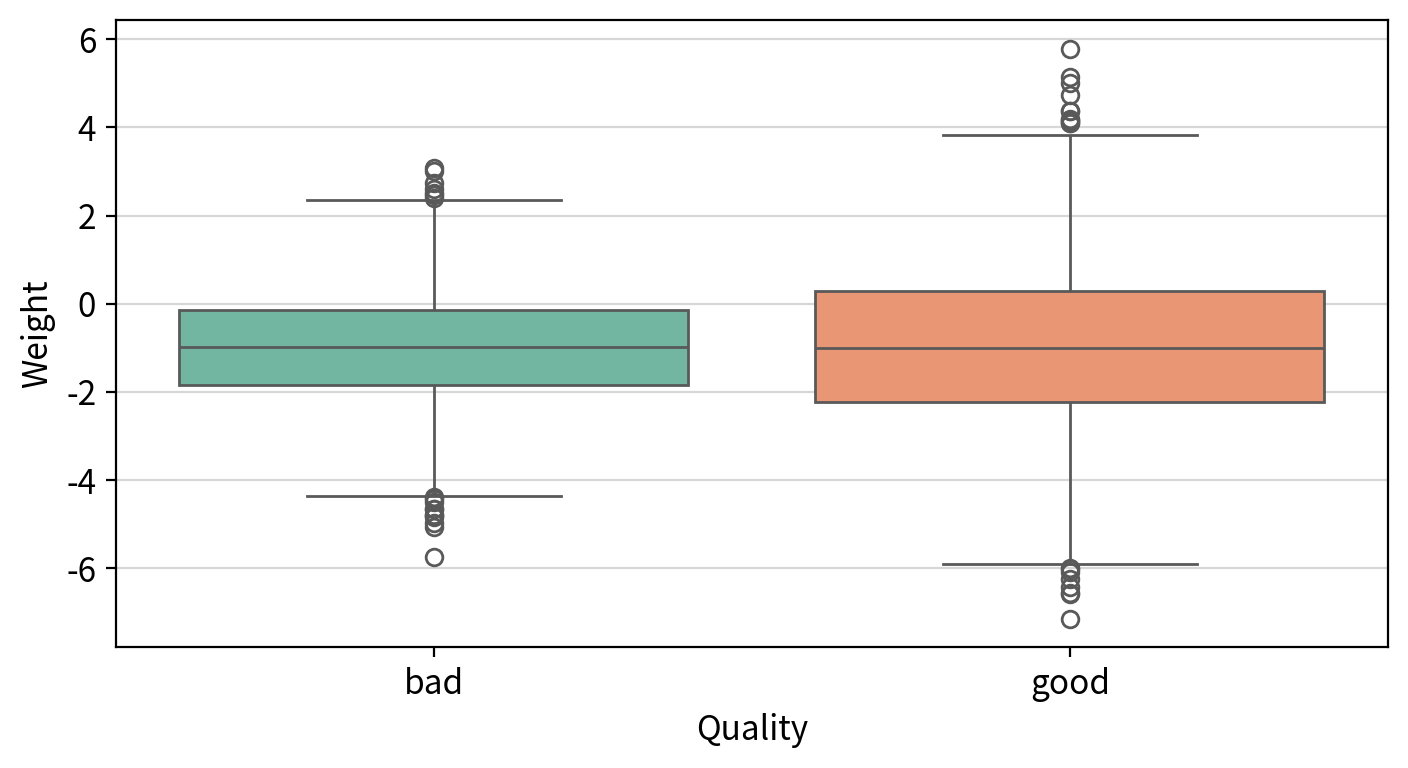

#### ▶︎ Sweetness(단맛 정도) → Quality

statistic  p-value  significant      result
test                alternative                                              
Mann-Whitney U test two-sided   1452149.000    0.000         True  bad ≠ good
                    less        1452149.000    0.000         True  bad < good
                    greater     1452149.000    1.000        False  bad ≤ good

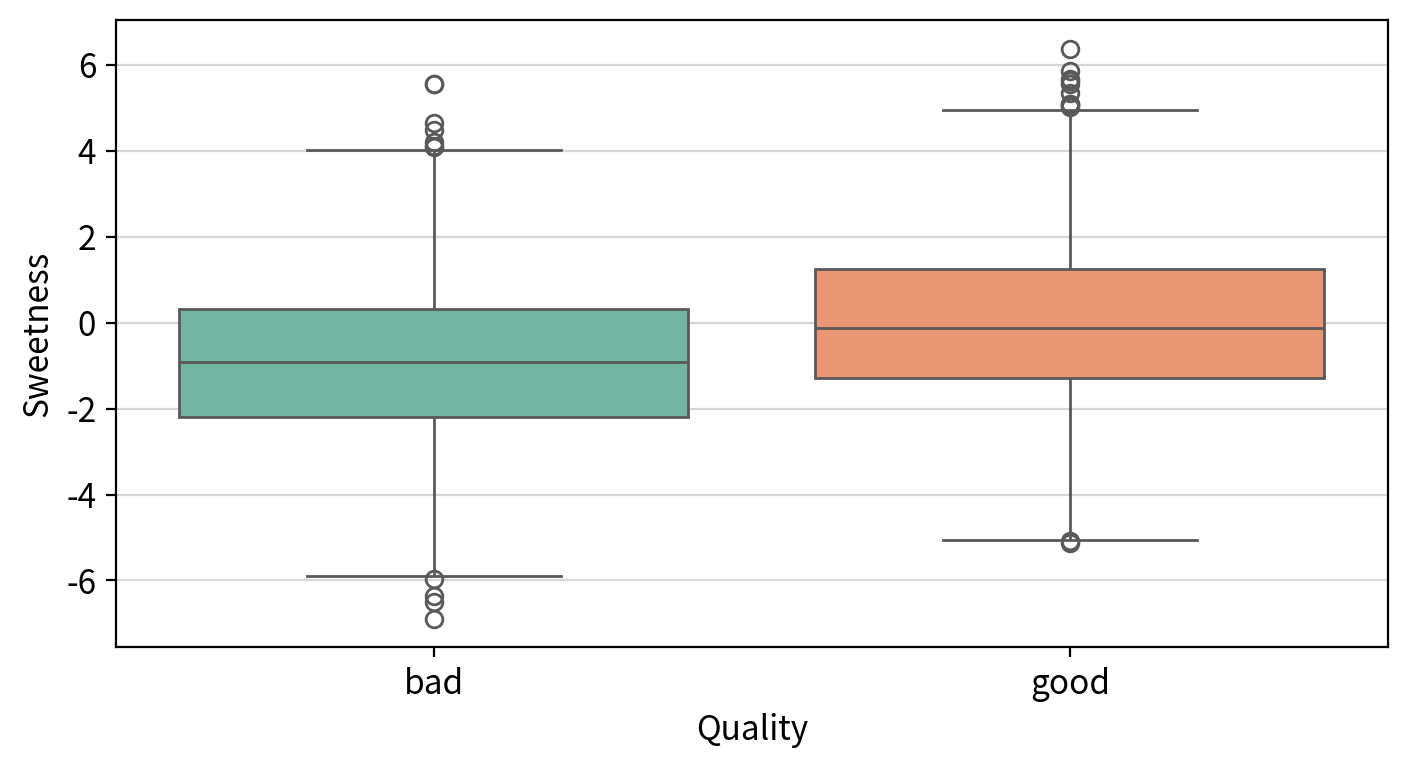

#### ▶︎ Crunchiness(아삭한 식감) → Quality

statistic  p-value  significant      result
test                alternative                                              
Mann-Whitney U test two-sided   1999316.000    0.985        False  bad = good
                    less        1999316.000    0.493        False  bad ≥ good
                    greater     1999316.000    0.507        False  bad ≤ good

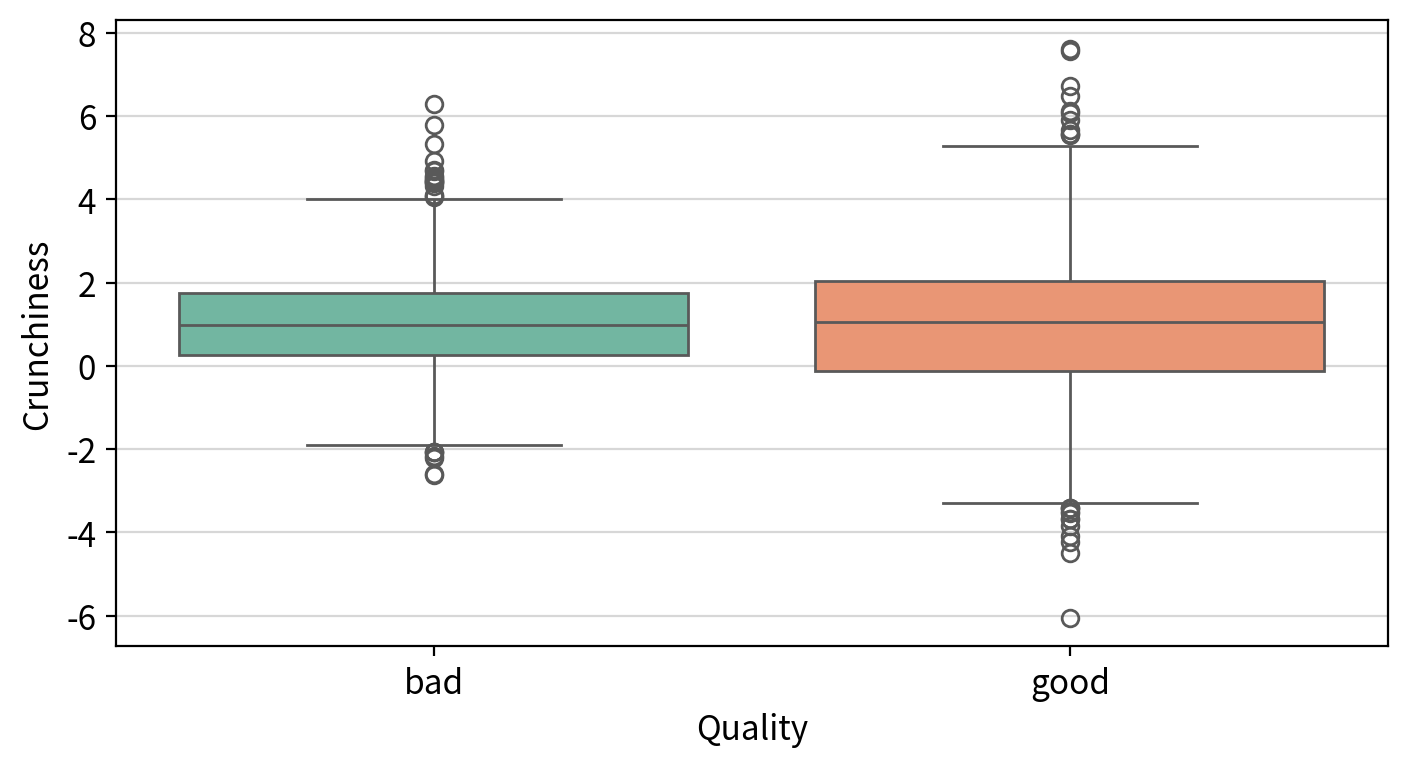

#### ▶︎ Juiciness(과즙 함량) → Quality

statistic  p-value  significant      result
test         alternative                                             
Welch t-test two-sided      -17.035    0.000         True  bad ≠ good
             less           -17.035    0.000         True  bad < good
             greater        -17.035    1.000        False  bad ≤ good

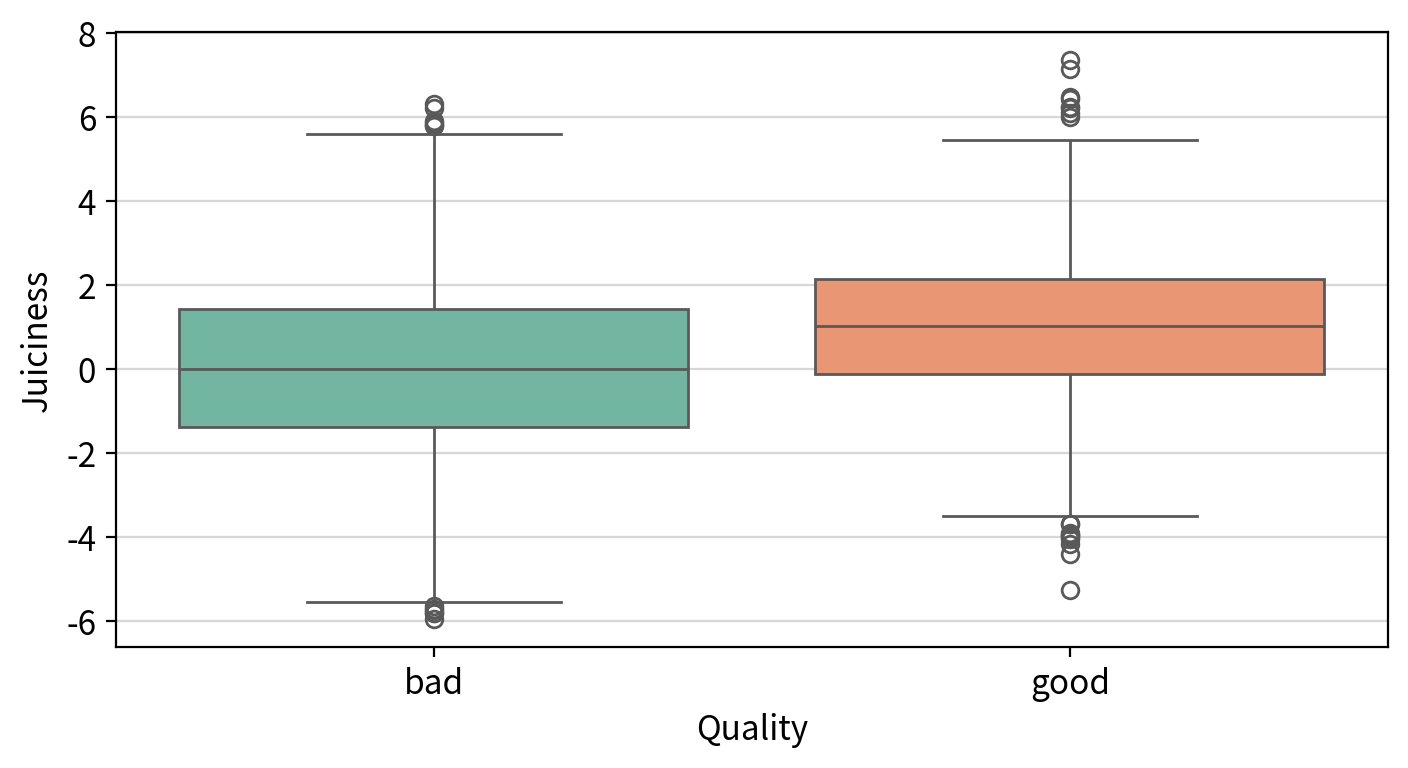

#### ▶︎ Ripeness(익은 정도) → Quality

statistic  p-value  significant      result
test         alternative                                             
Welch t-test two-sided       17.326    0.000         True  bad ≠ good
             less            17.326    1.000        False  bad ≥ good
             greater         17.326    0.000         True  bad > good

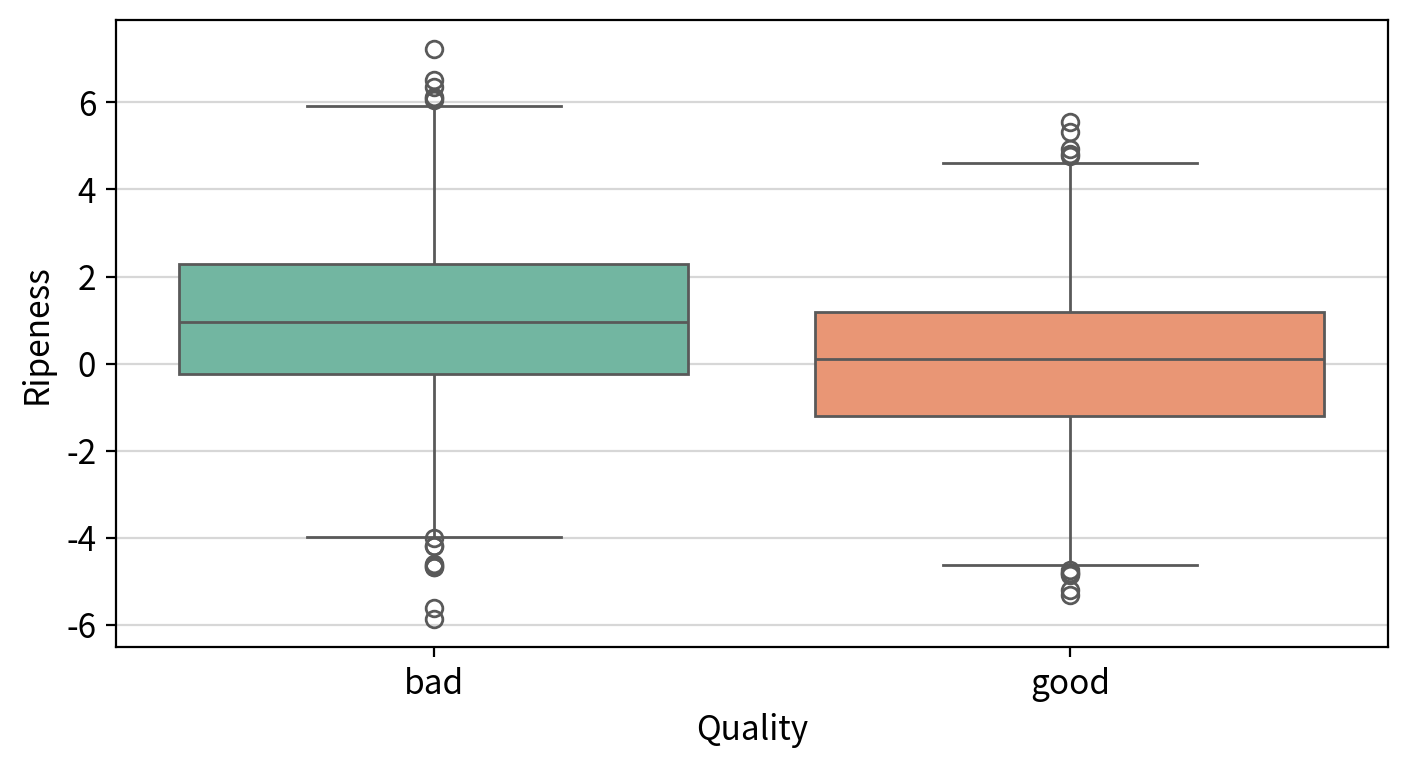

#### ▶︎ Acidity(산도) → Quality

statistic  p-value  significant      result
test                alternative                                              
Mann-Whitney U test two-sided   1990597.000    0.797        False  bad = good
                    less        1990597.000    0.399        False  bad ≥ good
                    greater     1990597.000    0.602        False  bad ≤ good

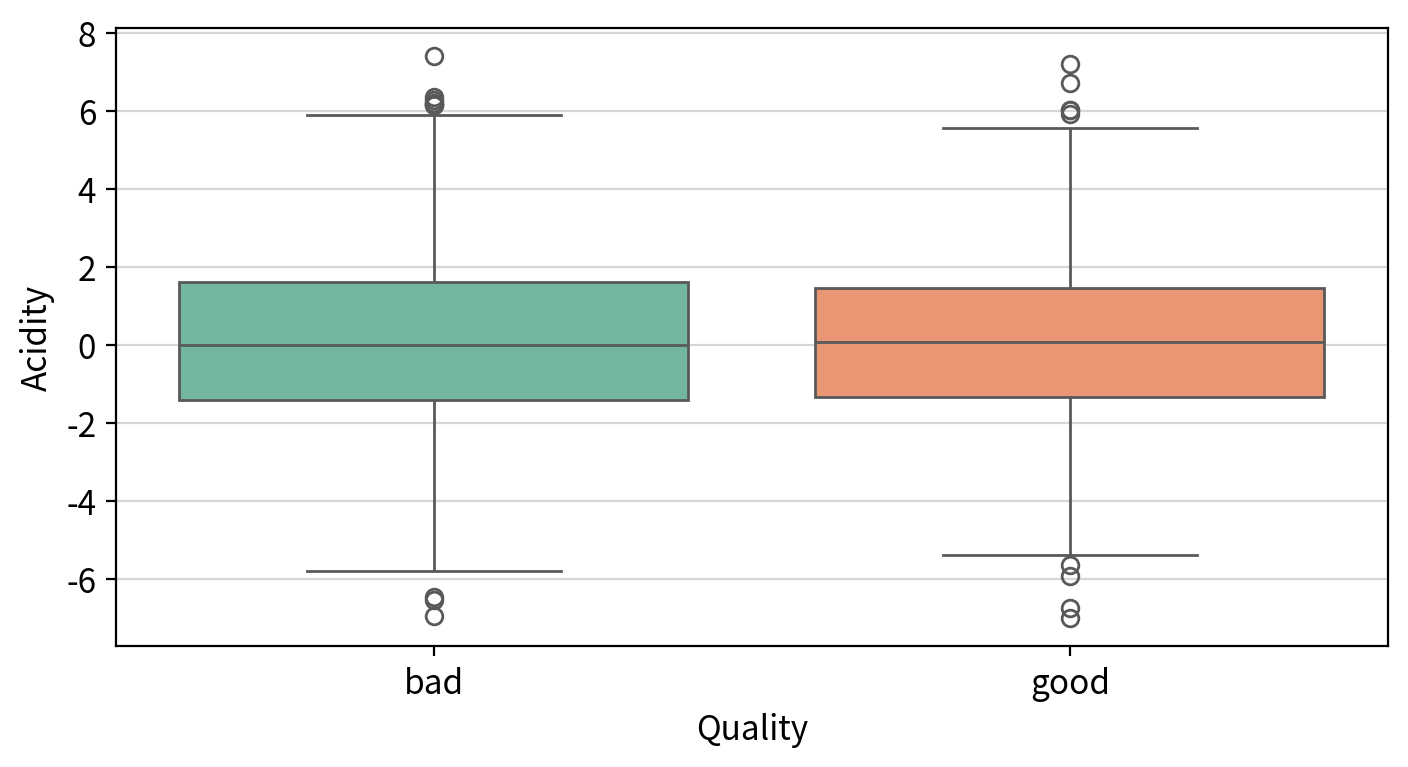

In [14]:
# 연속형 독립변수 이름을 탐색하면서 반복
for f in continuous_cols:
    # 빈 줄 출력용
    print()

    # 분석 단위 제목 출력
    display(Markdown(f"#### ▶︎ {f}({column_means[f]}) → {target}"))

    # 수집된 데이터가 long 타입이므로 검정 대상만 wide 타입으로 변환해야 한다.
    # -> 선형회귀 때와 hue/values 가 서로 뒤바뀐다. (종속변수가 집단 기준이 되므로)
    wide_df = my_prep.long2wide(df, hue=target, values=f)
    display(my_stats.test_independent(wide_df,
                group1=wide_df.columns[0], group2=wide_df.columns[1], plot=False))

    # 시각화: 종속변수 집단별 분포 비교
    my_plot.boxplot(data=df, x=target, y=f, hue=target, palette="Set2",
                    width=720, height=400)

#### 💡 인사이트

| 변수 | 검정 방법 | 유의확률 | 집단 차이 | 방향 | 단독 채택 |
|---|---|---|---|---|---|
| `Size` | Mann-Whitney U | < 0.001 | 유의 | `bad` < `good` | ✅ |
| `Sweetness` | Mann-Whitney U | < 0.001 | 유의 | `bad` < `good` | ✅ |
| `Ripeness` | T검정 | < 0.001 | 유의 | `bad` > `good` | ✅ |
| `Juiciness` | T검정 | < 0.001 | 유의 | `bad` < `good` | ✅ |
| `Weight` | T검정 | 0.928 | **차이 없음** | — | 🟡 보류 |
| `Acidity` | Mann-Whitney U | 0.797 | **차이 없음** | — | 🟡 보류 |
| `Crunchiness` | Mann-Whitney U | 0.985 | **차이 없음** | — | 🟡 보류 |

##### 교차분석 (x: 명목형 독립변수 → y: 명목형 종속변수)

- 명목형 독립변수가 있을 경우 카이제곱 독립성 검정을 수행한다.
  - 명목형 독립변수가 없을 경우 출력 결과가 없을 수 있다.

In [15]:
for n in nominal_cols:
    # 빈 줄 출력용
    print()

    # 분석 단위 제목 출력
    display(Markdown(f"#### ▶︎ {n}({column_means[n]}) → {target}"))

    # 교차분석 (카이제곱 독립성 검정)
    display(my_stats.chi2_independence(df, x=n, y=target, plot=False))

#### 💡 인사이트

> 이 데이터셋에는 **명목형 독립변수가 없으므로** 해당 없음. (출력 결과 없음)

#### 4-4. 다변량 분석 — 독립변수 간 상관

##### 독립변수간 상관 분석

- 연속형 독립변수끼리는 종속변수가 명목형이어도 상관분석을 그대로 쓸 수 있다.
- 목적이 다르다. 여기서는 **설명력 확인이 아니라 다중공선성 점검**이다.

In [16]:
corr = my_stats.multi_correlation(df, columns=continuous_cols, plot=False)
my_stats.correlation_summary(corr)

,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity
Size,1.000,-0.144,-0.325,0.172,-0.032,-0.155,0.210
Weight,-0.144,1.000,-0.120,-0.087,-0.091,-0.244,0.030
Sweetness,-0.325,-0.120,1.000,-0.017,0.098,-0.255,0.072
Crunchiness,0.172,-0.087,-0.017,1.000,-0.236,-0.184,0.074
Juiciness,-0.032,-0.091,0.098,-0.236,1.000,-0.124,0.231
Ripeness,-0.155,-0.244,-0.255,-0.184,-0.124,1.000,-0.195
Acidity,0.210,0.030,0.072,0.074,0.231,-0.195,1.000


,max-y,max-coef,count,columns
x,,,,
Size,Sweetness,-0.325,0,-
Sweetness,Size,-0.325,0,-
Ripeness,Sweetness,-0.255,0,-
Weight,Ripeness,-0.244,0,-
Crunchiness,Juiciness,-0.236,0,-
Juiciness,Crunchiness,-0.236,0,-
Acidity,Juiciness,0.231,0,-


#### 💡 인사이트

- `correlation_summary()`에서 **Strong(|r| ≥ 0.7) 조합이 하나도 나오지 않았다.**
- → **다중공선성 문제 없음.** 7개 변수를 모두 투입해도 계수가 불안정해지지 않는다.

#### 4-5. 최종 변수 선택

| 채택여부 | 변수 | 검정방법 | 유의확률 | 방향 | 공선성 신호 | 근거 |
|---|---|---|---|---|---|---|
| ✅ 채택 | `Size` | Mann-Whitney U | < 0.001 | `bad` < `good` | X (VIF 1.41) | 집단 차이 유의 |
| ✅ 채택 | `Sweetness` | Mann-Whitney U | < 0.001 | `bad` < `good` | X (VIF 1.48) | 집단 차이 유의 |
| ✅ 채택 | `Juiciness` | T검정 | < 0.001 | `bad` < `good` | X (VIF 1.22) | 집단 차이 유의 |
| ✅ 채택 | `Ripeness` | T검정 | < 0.001 | `bad` > `good` | X (VIF 1.48) | 집단 차이 유의 (유일한 음의 방향) |
| 🟡 보류 | `Weight` | T검정 | 0.928 | — | X (VIF 1.35) | 단독 차이는 없으나 **억제효과 가능성** → 투입 후 계수로 판정 |
| 🟡 보류 | `Acidity` | Mann-Whitney U | 0.797 | — | X (VIF 1.17) | 단독 차이는 없으나 **억제효과 가능성** → 투입 후 계수로 판정 |
| 🟡 보류 | `Crunchiness` | Mann-Whitney U | 0.985 | — | X (VIF 1.22) | 단독 차이는 없으나 **억제효과 가능성** → 투입 후 계수로 판정 |
| ❌ 제외 | `A_id` | — | — | — | — | 행마다 값이 다른 **식별자** (3-1에서 제거) |

- **제외는 `A_id` 하나뿐**이다. 나머지 7종은 전부 모델에 투입한 뒤 **후진소거법으로 판정**한다.
- 이유: 공선성이 없어 변수를 다 넣어도 부작용이 없고, T검정에서 탈락한 3종은 **다른 변수를 통제했을 때 살아날 수 있기 때문**이다.

## #5. 모델링

#### 5-1. 종속변수 라벨링

- 로지스틱 회귀의 종속변수는 **0/1의 정수**여야 한다. 문자열 `good`/`bad`를 숫자로 바꾼다.
- `my_prep.labeling()`은 **알파벳 순서**로 0부터 매긴다. → `bad = 0`, `good = 1`
- 즉 이 모형이 예측하는 것은 **P(Quality = good)** 이고,
  뒤에 나오는 오즈비는 모두 **"사과가 `good`일 오즈"** 에 대한 값이다.

In [17]:
base = my_prep.labeling(df, columns=[target])
base.head()

Quality (2 종): bad=0, good=1


,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity,Quality
0,-3.970,-2.512,5.346,-1.012,1.845,0.330,-0.492,1
1,-1.195,-2.839,3.664,1.588,0.853,0.868,-0.723,1
2,-0.292,-1.351,-1.738,-0.343,2.839,-0.038,2.622,0
3,-0.657,-2.272,1.325,-0.098,3.638,-3.414,0.791,1
4,1.364,-1.297,-0.385,-0.553,3.031,-1.304,0.502,1


#### 5-2. 기준선 모형 적합

In [18]:
fit_base = my_logit.fit_model(base, y=target)
my_logit.report_variables(fit_base, base)

,종속변수,독립변수,B,βstd,표준오차,z,유의확률,B 95% 하한,B 95% 상한,오즈비(OR),OR 95% 하한,OR 95% 상한,공차,VIF
0,Quality,Size,0.649,1.252,0.028,22.993,0.000,0.594,0.705,1.915,1.811,2.024,0.708,1.413
1,Quality,Sweetness,0.569,1.105,0.027,20.938,0.000,0.516,0.622,1.766,1.675,1.863,0.677,1.477
2,Quality,Juiciness,0.442,0.854,0.024,18.242,0.000,0.395,0.490,1.556,1.484,1.632,0.820,1.219
3,Quality,Acidity,-0.294,-0.621,0.021,-13.697,0.000,-0.336,-0.252,0.745,0.714,0.777,0.853,1.172
4,Quality,Weight,0.267,0.427,0.028,9.399,0.000,0.211,0.322,1.306,1.235,1.380,0.742,1.348
5,Quality,Ripeness,-0.127,-0.238,0.025,-5.132,0.000,-0.175,-0.078,0.881,0.839,0.925,0.677,1.478
6,Quality,Crunchiness,0.035,0.049,0.030,1.143,0.253,-0.025,0.094,1.035,0.976,1.098,0.821,1.218


#### 💡 인사이트 — EDA에서 탈락했던 변수가 되살아났다

| 변수 | T검정 (단독 비교) | 기준선 모형 (다른 변수 통제) | 판정 |
|---|---|---|---|
| `Size` | p < 0.001 | z = 22.99, p < 0.001 | 그대로 유의 |
| `Sweetness` | p < 0.001 | z = 20.94, p < 0.001 | 그대로 유의 |
| `Juiciness` | p < 0.001 | z = 18.24, p < 0.001 | 그대로 유의 |
| `Ripeness` | p < 0.001 | z = −5.13, p < 0.001 | 그대로 유의 |
| **`Acidity`** | **p = 0.797 (무관)** | **z = −13.70, p < 0.001** | **되살아남** |
| **`Weight`** | **p = 0.928 (무관)** | **z = 9.40, p < 0.001** | **되살아남** |
| `Crunchiness` | p = 0.985 (무관) | p = 0.253 | 유일한 탈락 후보 |

- **T검정에서 "차이가 전혀 없다"고 나왔던 `Acidity`와 `Weight`가 p < 0.001로 강하게 유의**해졌다.
  이것이 **억제효과(suppression)** 다. 다른 변수를 통제하지 않은 단독 비교에서는 효과가 가려져 있었던 것이다.
  - `Acidity`의 오즈비는 **0.745** 로, 산도가 1점 높아지면 `good`일 오즈가 **약 25.5% 감소**한다.
- → **EDA에서 유의하지 않다는 이유만으로 변수를 버리면 안 된다.**
- 유의하지 않은 변수는 `Crunchiness` 하나뿐이지만, **여기서도 아직 지우지 않는다.**

## #6. 모형 진단과 개선

#### 6-1. 가정 검토

##### 기준선 모형의 로짓 선형성 검정 (Box-Tidwell)

- 독립변수 x에 `x × ln(x)` 항을 추가해 **그 항이 유의한지** 본다.
  - 유의하면(p < 0.05) 로짓이 직선이 아니라는 뜻 → 변환·제곱항·구간화가 필요하다.

In [19]:
my_logit.test_linear(fit_base, base)

,z,p-value,linearity,위치이동,result
독립변수,,,,,
Size,4.323,0.000,False,True,대립가설 채택 → 로짓 선형성 위배(변환 필요)
Weight,11.161,0.000,False,True,대립가설 채택 → 로짓 선형성 위배(변환 필요)
Sweetness,0.605,0.545,True,True,귀무가설 채택 → 로짓 선형성 위배 근거 없음
Crunchiness,9.851,0.000,False,True,대립가설 채택 → 로짓 선형성 위배(변환 필요)
Juiciness,-8.075,0.000,False,True,대립가설 채택 → 로짓 선형성 위배(변환 필요)
Ripeness,-1.047,0.295,True,True,귀무가설 채택 → 로짓 선형성 위배 근거 없음
Acidity,-5.553,0.000,False,True,대립가설 채택 → 로짓 선형성 위배(변환 필요)


> **결과** — 7종 중 **5종이 위배**다. (`Weight` z = 11.16, `Crunchiness` z = 9.85, `Juiciness` z = −8.08, `Acidity` z = −5.55, `Size` z = 4.32)
> `Sweetness`(p = 0.545)와 `Ripeness`(p = 0.295)만 충족한다.
> **위배가 가장 심한 `Weight`부터 처방한다.**
>
> ※ 이 변수들은 음수를 포함하므로 `ln`의 정의역을 맞추기 위해 **최솟값이 1이 되도록 평행이동**한 뒤 검정된다. (`위치이동 = True`)

#### 6-2. 가정 위반에 대한 조치

##### 진단 → 처방 → 검증 → 재진단 루프

In [20]:
fit_fixed = my_logit.fix_linear(base, y=target)

[라운드 1] 위배 5종 → 'Weight' 처방 (z = 11.1613)
  → 제곱항 채택 (제곱항 p = 0.0000, 우도비 p = 0.0000e+00, AIC = 3962.44)
[라운드 2] 위배 5종 → 'Crunchiness' 처방 (z = 9.0855)
  → 제곱항 채택 (제곱항 p = 0.0000, 우도비 p = 0.0000e+00, AIC = 3867.27)
[라운드 3] 위배 3종 → 'Juiciness' 처방 (z = -10.5276)
  → 제곱항 채택 (제곱항 p = 0.0000, 우도비 p = 0.0000e+00, AIC = 3744.33)
[라운드 4] 위배 3종 → 'Acidity' 처방 (z = -7.4836)
  → 제곱항 채택 (제곱항 p = 0.0000, 우도비 p = 3.2307e-14, AIC = 3688.74)
[라운드 5] 위배 2종 → 'Ripeness' 처방 (z = -3.0869)
  → 제곱항 채택 (제곱항 p = 0.0023, 우도비 p = 2.1255e-03, AIC = 3681.30)
[라운드 6] 위배 1종 → 'Size' 처방 (z = 2.9542)
  → 제곱항 채택 (제곱항 p = 0.0025, 우도비 p = 2.2468e-03, AIC = 3673.97)
[라운드 7] 위배 변수 없음 → 루프 종료



,변수,처방,제곱항 p,검증 p,AIC,채택
라운드,,,,,,
1,Weight,제곱항,0.000,0.000,3962.440,True
2,Crunchiness,제곱항,0.000,0.000,3867.270,True
3,Juiciness,제곱항,0.000,0.000,3744.330,True
4,Acidity,제곱항,0.000,0.000,3688.740,True
5,Ripeness,제곱항,0.002,0.002,3681.300,True
6,Size,제곱항,0.003,0.002,3673.970,True


#### 💡 인사이트 — 하나씩 처방하니 `Crunchiness`도 해소됐다

- 6개 라운드에 걸쳐 **`Weight` → `Crunchiness` → `Juiciness` → `Acidity` → `Ripeness` → `Size`** 순으로
  위배가 심한 변수부터 하나씩 처방됐고, **7라운드에서 위배 변수가 사라져 루프가 종료**됐다.
  - `Sweetness`는 끝까지 위배로 잡히지 않아 **원본 그대로 남았다.**
- 라운드마다 위배 변수의 개수가 5 → 5 → 3 → 3 → 2 → 1 → 0으로 줄어드는데, **한 번에 하나씩 줄지 않는다.**
  한 변수를 고치면 다른 변수의 진단이 함께 바뀌기 때문이다. 이것이 재진단을 반드시 해야 하는 이유다.
- 처방 순서도 눈여겨볼 만하다. `Crunchiness`는 **T검정에서 p = 0.985로 완전 무관**이었고
  **기준선 모형에서도 p = 0.253으로 제거 후보**였는데, 로짓 선형성 진단에서는 **두 번째로 심한 위배**로 잡힌다.
  - 양 극단이 모두 `good` 쪽이라 평균 비교로는 상쇄되어 보이지 않았을 뿐이다.

##### 계층 원칙

- 제곱항을 넣으면 1차항이 유의하지 않게 나오는 경우가 있다. 후진소거법이라면 제거 대상이다.
- 하지만 **제곱항이 모형에 있으면 1차항은 유의하지 않아도 남긴다.** 이것을 **계층 원칙(hierarchy principle)** 이라 한다.
  - 1차항을 빼면 곡선의 **꼭짓점이 중심값에 고정**되어 버려, 데이터가 말하는 곡선 모양을 왜곡한다.
- 실제로 지워도 되는지는 **6-4의 성능 비교표**에서 후진소거 적용 모형과 나란히 놓고 판단한다.

#### 6-3. 관측치 독립성과 가정 검정 결과 확정

##### 관측치의 독립성 — Durbin-Watson

In [21]:
my_logit.test_independent(fit_fixed)

,statistic,independence,result
Durbin-Watson,2.022,True,독립성 만족


> **결과** — DW = **2.02**로 기준 범위(1.5 ~ 2.5)의 한가운데다. → **독립성 만족.**
> 사과 4,000개는 서로 다른 개체이고 수집 순서에 의미가 없으므로 설계상으로도 독립이 타당하다.

##### 가정 검정 결과 확정

- 처방 대상 변수 목록을 확정한다. 이 목록이 **다음 단계 파이프라인의 옵션**이 된다.

In [22]:
# 확정된 처방 내역 (변수별 처방 방식과 기준값)
recipe = fit_fixed.recipe_

for col, rule in recipe.items():
    print(f"{col:14s} : {rule['method']}")

extra_cols = [c for c in continuous_cols if c not in recipe]
print("\n처방 제외 (선형성 충족) :", extra_cols)
print("미해소 (구간화·스플라인 필요) :", fit_fixed.unresolved_)

Weight         : square
Crunchiness    : square
Juiciness      : square
Acidity        : square
Ripeness       : square
Size           : square

처방 제외 (선형성 충족) : ['Sweetness']
미해소 (구간화·스플라인 필요) : []


#### 6-4. 로지스틱 회귀 파이프라인

##### 전처리 체크포인트 정의

- 전처리 단계를 하나씩 누적한 체크포인트 (아래로 갈수록 전처리가 하나 더 붙는다)
- **0~3번은 가정 검정을 반영하지 않은 조합**, **4~7번은 `recipe`를 적용한 조합**이다.
  - 두 계열의 전처리 조합을 **동일하게 맞춰** 로짓 선형성 처방의 순수한 효과를 볼 수 있게 한다.
- 공선성 제거(`vif=True`)는 **모든 체크포인트에 공통으로** 걸어 둔다.
  - 4-4에서 이미 제거 대상이 없음을 확인했으므로, 별도의 비교 단계로 쪼갤 이유가 없다.

In [23]:
checkpoints = {
    # --- 가정 검정 미반영 ---
    "0_기준선":             dict(vif=True),
    "1_후진소거":           dict(backward=True, vif=True),
    "2_이상치대체":         dict(backward=True, outlier=True, vif=True),
    "3_정규화":             dict(backward=True, outlier=True, vif=True, scale=True),

    # --- 가정 검정 반영 (로짓 선형성 처방) ---
    "4_가정반영":           dict(recipe=recipe, vif=True),
    "5_가정반영+후진소거":   dict(recipe=recipe, backward=True, vif=True),
    "6_가정반영+이상치대체": dict(recipe=recipe, backward=True, outlier=True, vif=True),
    "7_가정반영+정규화":     dict(recipe=recipe, backward=True, outlier=True, vif=True, scale=True),
}

##### 체크포인트별 모델 적합

In [24]:
fits = {}    # 적합된 모델을 누적할 딕셔너리

for name in checkpoints:
    print(f"\n▶︎ --- {name} ---")

    fits[name] = my_logit.fit_pipeline(
        base, target, continuous_cols, name=name, **checkpoints[name])

print("\n누적된 모델 :", len(fits), "개")


▶︎ --- 0_기준선 ---

완료! 남은 변수: ['Acidity', 'Crunchiness', 'Juiciness', 'Ripeness', 'Size', 'Sweetness', 'Weight']
최대 VIF = 1.48


▶︎ --- 1_후진소거 ---

완료! 남은 변수: ['Acidity', 'Crunchiness', 'Juiciness', 'Ripeness', 'Size', 'Sweetness', 'Weight']
최대 VIF = 1.48

유의하지 않은 독립변수 제거 → Crunchiness (p = 0.2532)

▶︎ --- 2_이상치대체 ---

완료! 남은 변수: ['Acidity', 'Crunchiness', 'Juiciness', 'Ripeness', 'Size', 'Sweetness', 'Weight']
최대 VIF = 1.47

유의하지 않은 독립변수 제거 → Crunchiness (p = 0.3016)

▶︎ --- 3_정규화 ---

완료! 남은 변수: ['Acidity', 'Crunchiness', 'Juiciness', 'Ripeness', 'Size', 'Sweetness', 'Weight']
최대 VIF = 1.47

유의하지 않은 독립변수 제거 → Crunchiness (p = 0.3016)

▶︎ --- 4_가정반영 ---

완료! 남은 변수: ['Acidity_c', 'Acidity_c2', 'Crunchiness_c', 'Crunchiness_c2', 'Juiciness_c', 'Juiciness_c2', 'Ripeness_c', 'Ripeness_c2', 'Size_c', 'Size_c2', 'Sweetness', 'Weight_c', 'Weight_c2']
최대 VIF = 1.61


▶︎ --- 5_가정반영+후진소거 ---

완료! 남은 변수: ['Acidity_c', 'Acidity_c2', 'Crunchiness_c', 'Crunchiness_c2', 'Juiciness_c', 'Juiciness_c2'

##### 전체 모델 성능 비교

- 성능을 바꾼 것은 전처리가 아니라 가정 검정이었다

In [25]:
best = my_logit.compare_models(fits)
print("간명성 기준 1순위 :", best.name_)

,변수수,정확도,정밀도,재현율,F1,AUC,Pseudo R²,AIC,Gap(%)
모델,,,,,,,,,
5_가정반영+후진소거,12,0.791,0.784,0.804,0.794,0.868,0.343,3672.041,0.000
6_가정반영+이상치대체,12,0.793,0.787,0.805,0.796,0.868,0.341,3677.811,0.060
7_가정반영+정규화,12,0.793,0.787,0.805,0.796,0.868,0.341,3677.811,0.060
4_가정반영,13,0.792,0.785,0.804,0.795,0.868,0.343,3673.968,0.000
0_기준선,7,0.749,0.741,0.766,0.753,0.824,0.258,4129.557,5.080
1_후진소거,6,0.750,0.742,0.767,0.754,0.824,0.258,4128.863,5.090
2_이상치대체,6,0.749,0.741,0.766,0.754,0.823,0.257,4136.292,5.170
3_정규화,6,0.749,0.741,0.766,0.754,0.823,0.257,4136.292,5.170


간명성 기준 1순위 : 5_가정반영+후진소거


##### 최종 모델 선택

- `my_logit.compare_models()`는 근소 격차 그룹 안에서 **변수가 하나 적은 `5_가정반영+후진소거`를 1순위**로 지목한다.
- 하지만 5번이 지운 변수는 제곱항의 짝인 `Crunchiness_c`이므로, **계층 원칙**(6-2)에 따라 **4번을 채택**한다.
  - AIC 차이는 **1.93**(3673.97 → 3672.04)에 불과해, 변수 하나를 지워 얻는 이득이 거의 없다.
  - → **간명성 규칙이 통계적 원칙보다 앞설 수는 없다.** 자동 선택 결과는 언제나 분석자가 검토해야 한다.

In [26]:
# 계층 원칙에 따라 4번을 최종 채택한다
final_name = "4_가정반영"

final_fit = fits[final_name]
final_data = final_fit.data_       # 전처리가 끝난 데이터 (보고에 사용)

print("최종 모델 :", final_name)
print("독립변수  :", int(final_fit.df_model), "개")

최종 모델 : 4_가정반영
독립변수  : 13 개


## #7. 결과 해석

#### 7-1. 모형 적합도와 회귀계수 해석

##### 모형 적합도

In [27]:
Markdown(my_logit.report_fitness(final_fit))

**Note. n = 4000. LL = -1822.984, LL-Null = -2772.581, LLR χ²(13) = 1899.193, p < 0.001, Pseudo R² = 0.342**

Quality를 종속변수로, Sweetness, Weight_c, Weight_c2, Crunchiness_c, Crunchiness_c2, Juiciness_c, Juiciness_c2, Acidity_c, Acidity_c2, Ripeness_c, Ripeness_c2, Size_c, Size_c2(을)를 독립변수로 한 이항 로지스틱 회귀분석 결과, 모형은 통계적으로 유의하였다.

> LLR χ²(13) = 1899.193, p < 0.001, Pseudo R² = 0.342.

즉, 모형의 유사결정계수는 0.342로 매우 우수한 적합 수준을 보였다.

> ※ Pseudo R²는 선형회귀의 R²처럼 '분산 설명 비율'로 해석하지 않는다. 일반적으로 **0.2~0.4** 구간이면 매우 우수한 적합으로 본다.

##### 독립변수 보고

In [28]:
display(my_logit.report_variables(final_fit, final_data))
Markdown(my_logit.report_variables_text(final_fit, data=final_data))

,종속변수,독립변수,B,βstd,표준오차,z,유의확률,B 95% 하한,B 95% 상한,오즈비(OR),OR 95% 하한,OR 95% 상한,공차,VIF
0,Quality,Size_c,0.629,1.214,0.031,20.410,0.000,0.569,0.690,1.876,1.766,1.993,0.664,1.506
1,Quality,Sweetness,0.568,1.105,0.030,18.806,0.000,0.509,0.628,1.766,1.664,1.873,0.646,1.547
2,Quality,Juiciness_c,0.485,0.937,0.027,17.805,0.000,0.432,0.539,1.625,1.540,1.714,0.787,1.270
3,Quality,Acidity_c,-0.274,-0.578,0.023,-11.889,0.000,-0.319,-0.229,0.760,0.727,0.795,0.831,1.203
4,Quality,Crunchiness_c2,0.192,0.625,0.019,10.399,0.000,0.156,0.229,1.212,1.169,1.257,0.922,1.084
5,Quality,Ripeness_c,-0.184,-0.345,0.029,-6.378,0.000,-0.241,-0.127,0.832,0.786,0.880,0.622,1.609
6,Quality,Weight_c2,0.176,0.693,0.015,11.948,0.000,0.147,0.205,1.192,1.158,1.227,0.951,1.051
7,Quality,Weight_c,0.165,0.264,0.033,4.945,0.000,0.100,0.230,1.179,1.105,1.259,0.702,1.424
8,Quality,Juiciness_c2,-0.103,-0.547,0.010,-9.991,0.000,-0.123,-0.083,0.902,0.884,0.920,0.884,1.131
9,Quality,Acidity_c2,-0.061,-0.375,0.008,-7.590,0.000,-0.077,-0.045,0.941,0.926,0.956,0.893,1.120


- **Sweetness**의 회귀계수는 **B = 0.5685**, 오즈비는 **OR = 1.7656**로 나타났으며, 이는 **Quality**에 유의한 요인임을 의미한다. (**z = 18.81**, **p < .001**) 즉, **Sweetness**가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **76.6% 증가**하는 것으로 해석된다.
- **Weight_c**의 회귀계수는 **B = 0.165**, 오즈비는 **OR = 1.1794**로 나타났으며, 이는 **Quality**에 유의한 요인임을 의미한다. (**z = 4.94**, **p < .001**) 즉, **Weight_c**가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **17.9% 증가**하는 것으로 해석된다.
- **Weight_c2**의 회귀계수는 **B = 0.1758**, 오즈비는 **OR = 1.1922**로 나타났으며, 이는 **Quality**에 유의한 요인임을 의미한다. (**z = 11.95**, **p < .001**) 즉, **Weight_c2**가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **19.2% 증가**하는 것으로 해석된다.
- **Crunchiness_c**의 회귀계수는 **B = 0.0097**, 오즈비는 **OR = 1.0098**로 나타났으며, 이는 **Quality**에 유의하지 않은 요인임을 의미한다. (**z = 0.27**, **p = .787**) 즉, **Crunchiness_c**가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **1.0% 증가**하는 것으로 해석된다.
- **Crunchiness_c2**의 회귀계수는 **B = 0.1925**, 오즈비는 **OR = 1.2122**로 나타났으며, 이는 **Quality**에 유의한 요인임을 의미한다. (**z = 10.4**, **p < .001**) 즉, **Crunchiness_c2**가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **21.2% 증가**하는 것으로 해석된다.
- **Juiciness_c**의 회귀계수는 **B = 0.4853**, 오즈비는 **OR = 1.6247**로 나타났으며, 이는 **Quality**에 유의한 요인임을 의미한다. (**z = 17.81**, **p < .001**) 즉, **Juiciness_c**가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **62.5% 증가**하는 것으로 해석된다.
- **Juiciness_c2**의 회귀계수는 **B = -0.1031**, 오즈비는 **OR = 0.902**로 나타났으며, 이는 **Quality**에 유의한 요인임을 의미한다. (**z = -9.99**, **p < .001**) 즉, **Juiciness_c2**가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **9.8% 감소**하는 것으로 해석된다.
- **Acidity_c**의 회귀계수는 **B = -0.274**, 오즈비는 **OR = 0.7603**로 나타났으며, 이는 **Quality**에 유의한 요인임을 의미한다. (**z = -11.89**, **p < .001**) 즉, **Acidity_c**가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **24.0% 감소**하는 것으로 해석된다.
- **Acidity_c2**의 회귀계수는 **B = -0.061**, 오즈비는 **OR = 0.9408**로 나타났으며, 이는 **Quality**에 유의한 요인임을 의미한다. (**z = -7.59**, **p < .001**) 즉, **Acidity_c2**가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **5.9% 감소**하는 것으로 해석된다.
- **Ripeness_c**의 회귀계수는 **B = -0.184**, 오즈비는 **OR = 0.8319**로 나타났으며, 이는 **Quality**에 유의한 요인임을 의미한다. (**z = -6.38**, **p < .001**) 즉, **Ripeness_c**가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **16.8% 감소**하는 것으로 해석된다.
- **Ripeness_c2**의 회귀계수는 **B = -0.0309**, 오즈비는 **OR = 0.9696**로 나타났으며, 이는 **Quality**에 유의한 요인임을 의미한다. (**z = -3.02**, **p = .002**) 즉, **Ripeness_c2**가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **3.0% 감소**하는 것으로 해석된다.
- **Size_c**의 회귀계수는 **B = 0.6294**, 오즈비는 **OR = 1.8765**로 나타났으며, 이는 **Quality**에 유의한 요인임을 의미한다. (**z = 20.41**, **p < .001**) 즉, **Size_c**가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **87.6% 증가**하는 것으로 해석된다.
- **Size_c2**의 회귀계수는 **B = 0.029**, 오즈비는 **OR = 1.0294**로 나타났으며, 이는 **Quality**에 유의한 요인임을 의미한다. (**z = 3.02**, **p = .003**) 즉, **Size_c2**가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **2.9% 증가**하는 것으로 해석된다.

> ※ 오즈비(OR)가 1보다 크면 사건 발생 오즈가 증가, 1보다 작으면 감소함을 뜻한다. 유의확률이 유의수준보다 큰(=유의하지 않은) 변수는 효과가 통계적으로 확인되지 않았으므로 오즈비 해석에 주의한다. 더미변수의 오즈비는 '기준(drop_first로 제외된) 범주' 대비 값이다.

> ※ **오즈비(OR)의 크기로 변수의 영향력을 비교하면 안 된다.**
> 변수 간 값의 범위가 동일한 경우만 오즈비를 직접 비교할 수 있다.
> 값의 범위가 서로 다르면 범위를 통일한 **표준화 계수(βstd)** 로 영향력을 비교해야 한다.

##### 오즈비 시각화

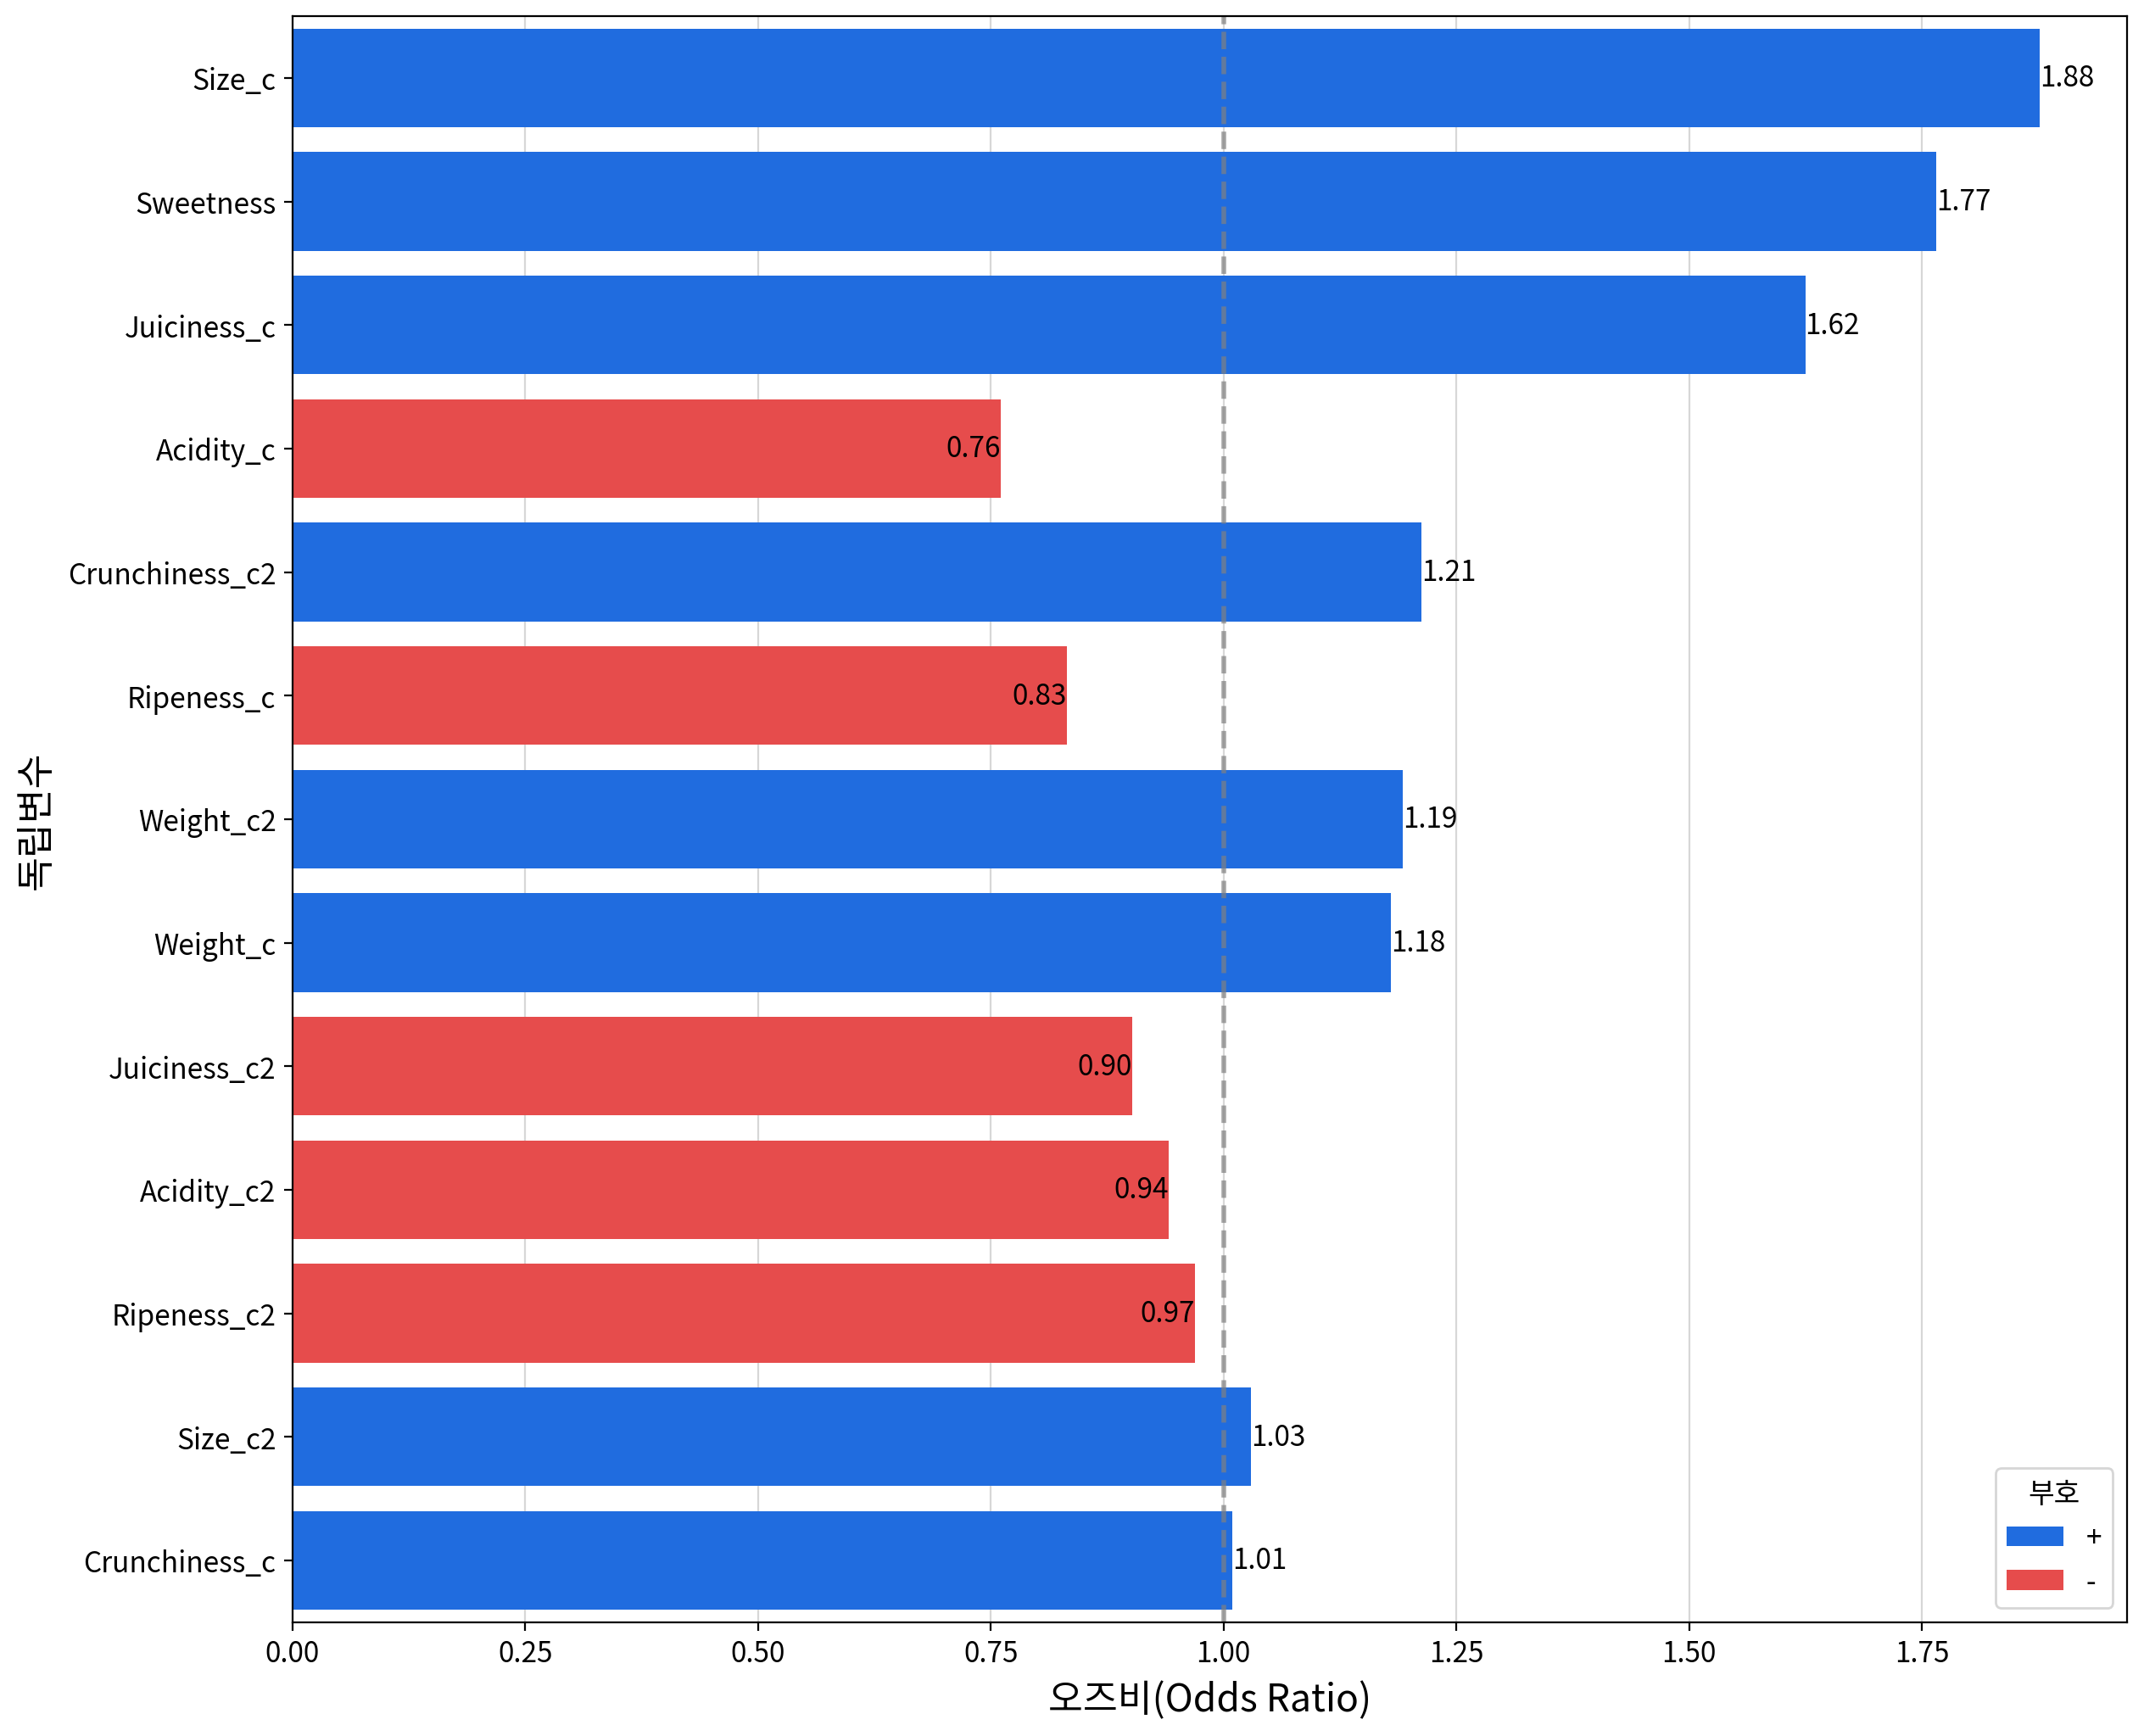

In [29]:
my_logit.plot_odds(final_fit, final_data)

#### 💡 인사이트 — 계수 해석

**모형 요약** — `logit(P(Quality = good)) ~ Sweetness + (Size·Weight·Crunchiness·Juiciness·Ripeness·Acidity의 1차항 + 제곱항)`

- **LLR χ²(13) = 1,899.19, p < .001, Pseudo R² = 0.342** 로 매우 우수한 적합이다. 13개 중 12개가 유의하다.
- **영향력 1위는 `Size`** 다. 표준화 계수 βstd = 1.214로 2위 `Sweetness`(1.105)와 근소하고,
  이어서 `Juiciness`(0.937) 순이다. **크기·단맛·과즙이 품질을 결정하는 3대 축**이다.

**1차항만 있는 변수 (직선 관계)**

| 변수 | 오즈비 | 해석 |
|---|---|---|
| `Sweetness` | 1.766 | 단맛 1점 ↑ → `good`일 오즈 **76.6% 증가** |

**1차항 + 제곱항이 있는 변수 (곡선 관계)**

⚠️ 제곱항이 있는 변수는 **오즈비를 한 줄로 해석하지 않는다.** 두 계수가 함께 곡선을 만든다.

| 변수 | 1차항 B | 제곱항 B | 곡선 모양 | 해석 |
|---|---|---|---|---|
| `Size` | +0.629 | +0.029 | 아래로 볼록 ∪ | 클수록 좋고, 커질수록 **가속**된다 |
| `Weight` | +0.165 | +0.176 | 아래로 볼록 ∪ | 평균에서 **양쪽으로 멀어질수록** 좋다 |
| `Crunchiness` | +0.010 (n.s.) | +0.192 | 아래로 볼록 ∪ | 아삭함은 **극단(아주 아삭하거나 아주 무르거나)** 이 좋다 |
| `Juiciness` | +0.485 | −0.103 | 위로 볼록 ∩ | 과즙은 많을수록 좋지만 **어느 지점부터 효과가 꺾인다** |
| `Ripeness` | −0.184 | −0.031 | 위로 볼록 ∩ | 덜 익을수록 좋고, **과숙일수록 급격히 나빠진다** |
| `Acidity` | −0.274 | −0.061 | 위로 볼록 ∩ | 산도가 높을수록 나쁘고, **높아질수록 가속**된다 |

- **`Crunchiness`가 이 분석의 가장 큰 반전이다.**
  T검정 p = 0.985(완전 무관), 기준선 모형 p = 0.253(제거 대상)이었던 변수가
  **제곱항을 넣자 z = 10.40으로 유의한 예측 변수**(|z| 기준 6번째, βstd 기준 5번째)가 됐다.
  1차항으로만 보면 효과가 없는 이유는, **양 극단이 모두 `good` 쪽이라 평균적으로 상쇄**되기 때문이다.
- 이것은 EDA와 모델링 단계에서 각각 다른 이유로 놓칠 수 있었던 변수다.
  - EDA(T검정) → 평균 비교라서 U자 관계를 못 본다.
  - 기준선 모형 → 직선만 표현하므로 역시 못 본다.
  - **가정 검정(Box-Tidwell)에서만 잡힌다.**

#### 7-2. 분류 성능 평가와 임계값 조정

##### 분류 성능 평가

,예측 0 (Negative),예측 1 (Positive)
실제 0 (Negative),1555,441
실제 1 (Positive),392,1612


,정확도(Accuracy),정밀도(Precision),"재현율(Recall,TPR)","위양성율(Fallout,FPR)","특이성(Specificity,TNR)",F1,AUC,AUC 판단,진단오즈비(DOR)
performance,0.792,0.785,0.804,0.221,0.779,0.795,0.868,우수,14.500


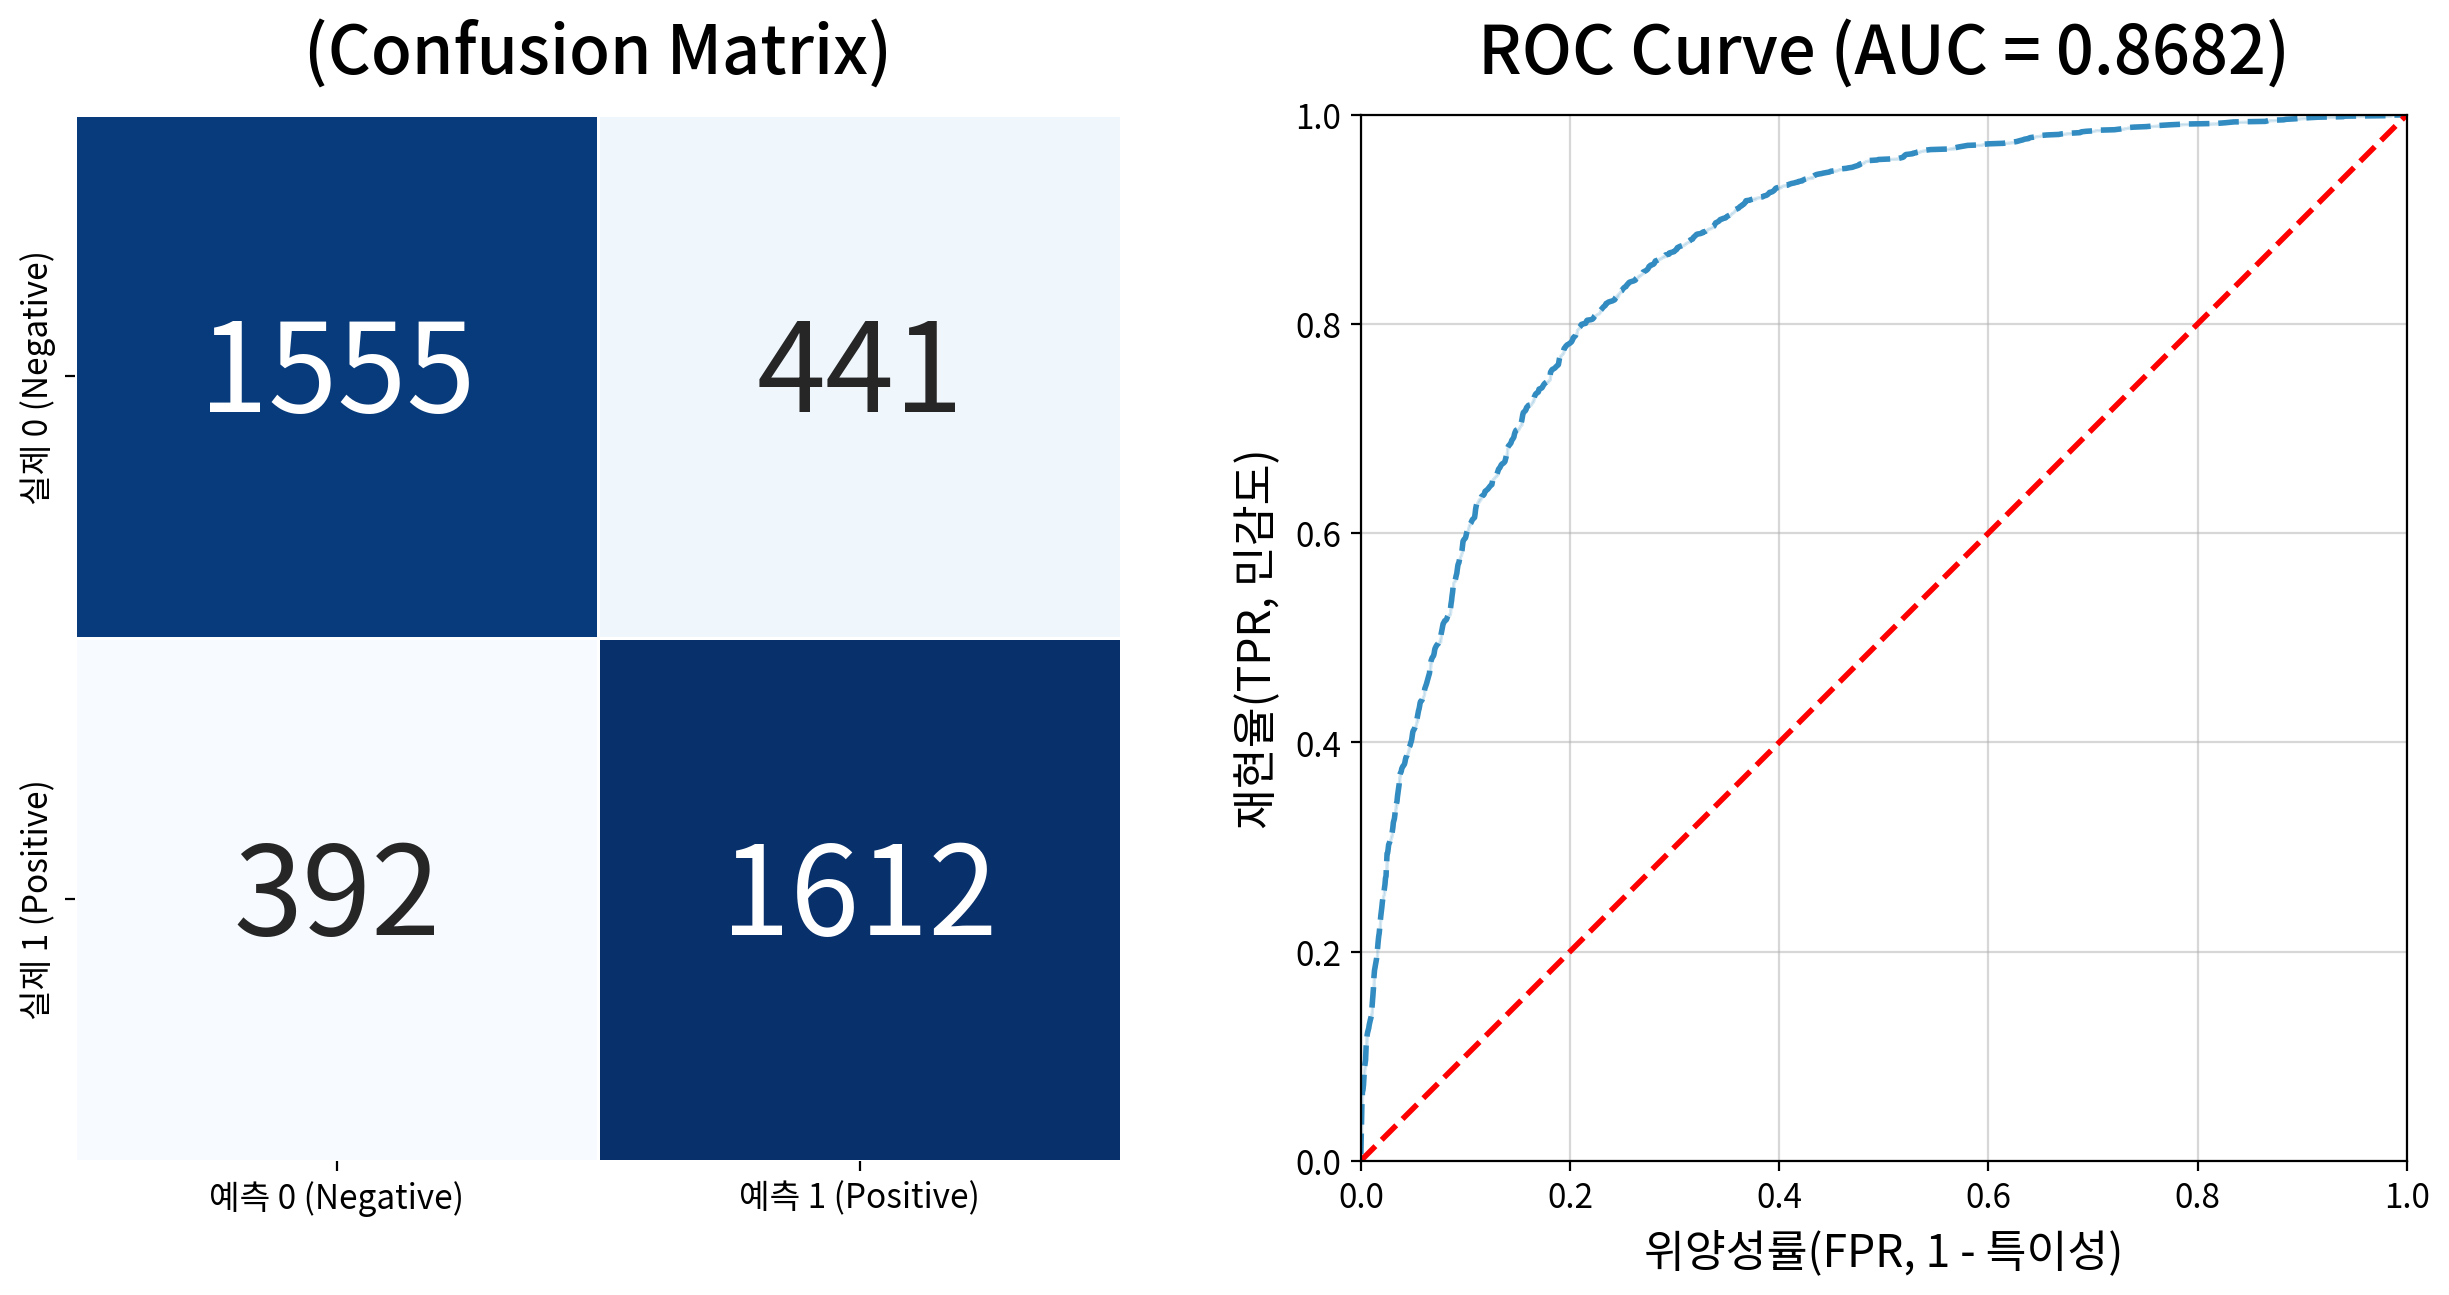

In [30]:
my_logit.report_performance(final_fit)

#### 💡 인사이트

- **정확도 0.792** — 4,000개 중 3,167개를 맞혔다. 게으른 모형의 바닥값 50.1%보다 **29%p 높다.**
- **AUC 0.868 (우수)** — `good` 사과 하나와 `bad` 사과 하나를 무작위로 뽑았을 때,
  모형이 `good` 쪽에 더 높은 확률을 줄 가능성이 **86.8%** 다.
- **정밀도 0.785 · 재현율 0.804 · 특이성 0.779로 네 지표가 고르다.**
  균형 데이터이기 때문에 나타나는 특징이다.
- **진단 오즈비 14.50** — 모형이 `good`이라고 판정한 사과가 실제로 `good`일 오즈는
  `bad`라고 판정한 사과의 **약 14.5배**다.

##### 임계값 조정

- 임계값 0.5는 관례일 뿐 **정답이 아니다.** 목적에 따라 조정한다.

In [31]:
my_logit.report_threshold(final_fit)

,정확도,정밀도,재현율,F1,놓친 1(FN),잘못 잡은 0(FP)
임계값,,,,,,
0.300,0.765,0.699,0.932,0.799,137,803
0.400,0.784,0.740,0.875,0.802,250,615
0.500,0.792,0.785,0.804,0.795,392,441
0.600,0.779,0.822,0.713,0.764,575,309
0.700,0.747,0.857,0.594,0.702,813,198


#### 💡 인사이트

- **정확도는 0.5에서 최대(0.792)** 지만, **F1은 0.4에서 최대(0.802)** 다.
- **트레이드오프가 그대로 나타난다.** 임계값 0.3 → 재현율 0.932 / 정밀도 0.699,
  임계값 0.7 → 정밀도 0.857 / 재현율 0.594.
- **정답은 목적이 정한다.**
  - **프리미엄 등급 선별**(내보내는 사과는 반드시 `good`이어야 함) → 임계값을 **높여** 정밀도 확보
  - **폐기 대상 걸러내기**(좋은 사과를 버리면 손해) → 임계값을 **낮춰** 재현율 확보

#### 7-3. 질문별 답변과 가설 판정

> 최종 채택 모형 `4_가정반영`(= `final_fit`, 독립변수 13개)의 결과를 바탕으로 #1의 분석 질문과 #2-3의 가설에 답한다.
> (7-1 `report_fitness`·`report_variables`, 7-2 `report_performance` 출력 기준)

**Q1. 사과가 `good`일 확률을 가장 크게 좌우하는 요인은 무엇인가?**

| 순위 | 변수 | 표준화계수(βstd) | 오즈비(OR) |
|---|---|---|---|
| 1 | `Size_c` | **1.214** | 1.876 |
| 2 | `Sweetness` | 1.105 | 1.766 |
| 3 | `Juiciness_c` | 0.937 | 1.625 |

- 근거: 오즈비는 변수 간 값의 범위가 다르면 직접 비교할 수 없어 **βstd로 영향력을 비교**함(7-1 안내문 기준).
- **답: 크기(`Size`)임.** 2위 `Sweetness`(1.105)와는 근소하며, 크기·단맛·과즙이 상위 3개 축임.
  - `Size`는 제곱항(`Size_c2` B = +0.029)도 유의하므로 오즈비 1.876을 한 줄로 해석하지 않음.

**Q2. EDA에서 품질과 무관해 보였던 변수는 다른 변수를 통제하면 어떻게 되는가?**

| 변수 | T검정 / Mann-Whitney U (단독) | 기준선 모형 (다른 변수 통제) | 최종 모형 |
|---|---|---|---|
| `Acidity` | p = 0.797 (차이 없음) | z = −13.70, p < .001, OR = 0.745 | `Acidity_c` z = −11.89, p < .001 |
| `Weight` | p = 0.928 (차이 없음) | z = 9.40, p < .001, OR = 1.306 | `Weight_c2` z = 11.95, p < .001 |
| `Crunchiness` | p = 0.985 (차이 없음) | z = 1.14, p = 0.253 (비유의) | `Crunchiness_c` p = 0.787 (비유의) / **`Crunchiness_c2` z = 10.40, p < .001** |

- **답: 세 변수 모두 단독 비교에서는 무관했지만, 모형에서는 `Acidity`·`Weight`가 기준선에서 먼저 유의해졌고 `Crunchiness`는 제곱항을 넣자 유의해짐.**
  - `Acidity`·`Weight`: 다른 변수를 통제했을 때 효과가 드러남(억제효과). `Acidity`는 1점 오르면 `good`일 오즈가 약 25.5% 감소함(OR 0.745, 기준선 모형).
  - `Crunchiness`: 1차항은 끝까지 비유의지만 제곱항이 양(+)이고 유의함(B = +0.192). **EDA의 평균 비교와 직선만 표현하는 기준선 모형에서는 보이지 않다가 가정 검정(Box-Tidwell)에서 잡힘.**
  - → **EDA에서 유의하지 않다는 이유만으로 변수를 버리면 안 됨.**

**Q3. 로짓 선형성은 충족되는가? 처방으로 성능이 얼마나 달라지는가?**

| 구분 | 모델 | 변수 수 | 정확도 | AUC | Pseudo R² | AIC |
|---|---|---|---|---|---|---|
| 가정 미반영 | `0_기준선` | 7 | 0.749 | 0.824 | 0.258 | 4,129.557 |
| 가정 반영 (최종) | `4_가정반영` | 13 | **0.792** | **0.868** | **0.343** | **3,673.968** |

- 근거 ① Box-Tidwell 결과 7종 중 **5종이 위배**임(`Weight` z = 11.16, `Crunchiness` z = 9.85, `Juiciness` z = −8.08, `Acidity` z = −5.55, `Size` z = 4.32). 충족한 변수는 `Sweetness`(p = 0.545)·`Ripeness`(p = 0.295)임.
- 근거 ② 진단 → 처방 루프 6라운드에서 6개 변수에 **제곱항을 추가**했고, 7라운드에서 위배 변수가 없어져 종료됨. 독립성은 DW = 2.022로 만족함.
- **답: 선형성은 충족되지 않았고(5종 위배), 제곱항 처방 후 해소됨. 정확도 0.749 → 0.792, AUC 0.824 → 0.868, AIC 4,129.557 → 3,673.968로 개선됨.**
  - 성능을 바꾼 것은 이상치 대체·정규화 같은 전처리가 아니라 **가정 검정에 따른 처방**이었음. 가정 미반영 4종은 AUC 0.823~0.824, 가정 반영 4종은 모두 0.868임.

**Q4. 최종 모형의 분류 성능은 어느 정도이며, 임계값은 어떻게 정해야 하는가?**

| 지표 | 값 |
|---|---|
| 정확도 | 0.792 (4,000건 중 3,167건 정분류, 바닥값 50.1% 대비 +29%p) |
| AUC | 0.868 (우수) |
| 정밀도 / 재현율 / 특이성 / F1 | 0.785 / 0.804 / 0.779 / 0.795 |
| 진단오즈비(DOR) | 14.50 |

| 임계값 | 정확도 | 정밀도 | 재현율 | F1 |
|---|---|---|---|---|
| 0.3 | 0.765 | 0.699 | 0.932 | 0.799 |
| 0.4 | 0.784 | 0.740 | 0.875 | **0.802** |
| **0.5** | **0.792** | 0.785 | 0.804 | 0.795 |
| 0.6 | 0.779 | 0.822 | 0.713 | 0.764 |
| 0.7 | 0.747 | 0.857 | 0.594 | 0.702 |

- **답: 정확도 0.792, AUC 0.868이며 네 지표(정밀도·재현율·특이성·F1)가 0.78~0.80으로 고름.** 정확도는 임계값 0.5에서, F1은 0.4에서 최대임.
  - 임계값은 목적이 정함. 프리미엄 등급 선별은 **높여서 정밀도**를, 폐기 대상 걸러내기는 **낮춰서 재현율**을 확보함.

**가설 판정**

| 가설 | 채택 / 기각 | 근거 |
|---|---|---|
| H1. 단맛·과즙 ↑ → `good` 오즈 ↑ | **채택** (과즙은 단서 있음) | `Sweetness` B = +0.568, OR = 1.766, p < .001 / `Juiciness_c` B = +0.485, OR = 1.625, p < .001. 단 `Juiciness_c2` B = −0.103으로 곡선(위로 볼록)이라 과즙이 많을수록 효과가 꺾임 |
| H2. 7개 특성 모두 단독으로 품질과 관련 | **기각** | 7종 중 4종(`Size`·`Sweetness`·`Juiciness`·`Ripeness`)만 유의. `Weight` p = 0.928, `Acidity` p = 0.797, `Crunchiness` p = 0.985는 차이 없음 |
| H3. 7개 모두 로짓 선형성 충족 | **기각** | Box-Tidwell 5종 위배 (`Weight` z = 11.16 최대). 제곱항 처방 후 해소 |
| H4. 최종 모형이 정확도 50.1% 바닥값보다 우수 | **채택** | LLR χ²(13) = 1,899.193, p < .001, Pseudo R² = 0.342, 정확도 0.792, AUC 0.868 (단, 학습 데이터 기준) |

**핵심 인사이트**

1. **영향력 1위는 크기임.** βstd 기준 `Size_c`(1.214) > `Sweetness`(1.105) > `Juiciness_c`(0.937)임.
2. **단독 검정에서 무관하다고 변수를 버리면 안 됨.** `Acidity`·`Weight`는 다른 변수를 통제하자 p < .001로 유의해졌고, `Crunchiness`는 제곱항에서 유의해짐.
3. **성능을 바꾼 것은 가정 검정이었음.** 이상치 대체·정규화는 AUC를 바꾸지 못했고(0.823~0.824), 제곱항 처방이 0.868로 끌어올림.
4. **자동 선택 결과는 분석자가 검토해야 함.** `compare_models()`는 변수가 1개 적은 `5_가정반영+후진소거`를 1순위로 지목했지만, 지운 변수가 제곱항의 짝(`Crunchiness_c`)이라 **계층 원칙에 따라 `4_가정반영`을 채택**함. AIC 차이는 1.93에 불과함.
5. **균형 데이터라 정확도를 그대로 신뢰할 수 있음.** `good` 2,004건 : `bad` 1,996건이라 바닥값이 50.1%임.


#### 7-4. 활용과 한계

**활용**

- **적용 범위:** Kaggle Apple Quality 데이터(표준화된 지표, 4,000건)에서 품질 판정 구조를 설명하는 용도에 한정됨.
- **임계값:** 0.5는 관례일 뿐이며 목적에 따라 정함. 프리미엄 선별은 높여서 정밀도를, 폐기 대상 걸러내기는 낮춰서 재현율을 확보함(7-2).
- **계수의 의미:** 특성과 품질이 함께 움직이는 정도를 보여주는 **기술적 요약**임.

**한계**

- **처방을 고르는 절차가 자동 규칙에 의존한다.** 제곱항과 로그 변환 중 AIC가 낮은 쪽을 고르도록 했지만,
  실제로는 **로짓 대비 산점도의 모양을 보고 판단**하는 것이 원칙이다. 이 데이터는 7종 모두 음수를 포함해
  로그 변환이 후보에서 빠졌으므로, 사실상 제곱항 외의 선택지가 없었다.
- **제곱항을 6개 추가하면서 모형이 복잡해졌다.** 곡선을 표현할 수 있게 된 대신
  변수당 계수가 2개로 늘어 **오즈비를 한 줄로 해석할 수 없게 됐고**, 과적합 위험도 함께 올라갔다.
- **성능을 학습 데이터에서 그대로 측정했다.** 훈련·검증 데이터를 나누지 않았으므로
  정확도 0.792와 AUC 0.868은 **낙관적인 값**이다. 제곱항 6개를 추가하면서 과적합 위험도 함께 올라갔다.
- **변수의 물리적 의미를 알 수 없다.** 값이 이미 표준화된 상태로 제공되어
  "크기 1점"이 몇 mm인지, "산도 1점"이 pH 얼마인지 알 수 없다. **오즈비를 현장 단위로 환산할 수 없다.**
- **품질 라벨의 기준이 공개되어 있지 않다.** `good`/`bad`를 누가 어떤 기준으로 판정했는지 모르므로,
  모형이 학습한 것은 "사과의 객관적 품질"이 아니라 **"이 데이터를 만든 사람의 판정 기준"** 일 수 있다.
- **인과관계가 아니라 연관관계다.** 산도를 인위적으로 낮춘다고 사과가 `good`이 되지는 않는다.

**다음에 시도할 것**

- 훈련·검증 데이터를 나누거나 교차검증을 적용해 정확도·AUC를 일반화 가능한 값으로 재측정
- 사용 목적(정밀도 우선 / 재현율 우선)을 정한 뒤 그에 맞는 임계값으로 재평가
